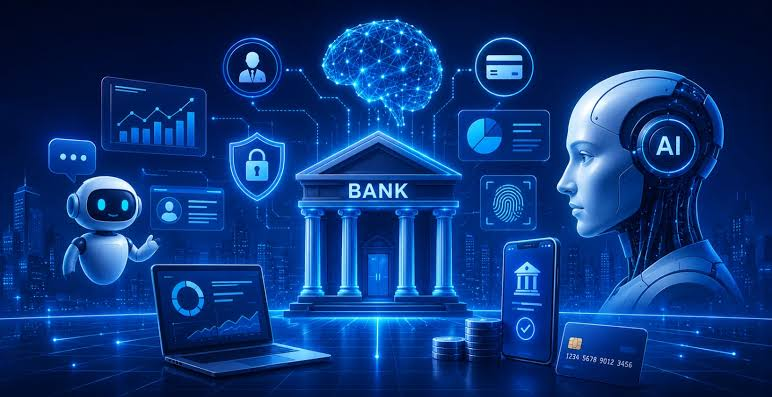

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🏦 Project Objective
</h2>

<p style="font-size:16px; line-height:1.8;">

The main objective of this project is to develop a machine learning model that can predict which bank customers are more likely to accept a <b>Personal Loan</b> offer. 
Using customer information such as income, experience, family size, education, credit card spending, and banking services, the model identifies customers with a higher probability of accepting a loan.

</p>

<p style="font-size:16px; line-height:1.8;">

This project can help the bank make <b>smarter and more targeted marketing decisions</b>. 
Instead of offering personal loans to all customers, the bank can focus its campaigns on customers who are more likely to respond positively. 
This can reduce unnecessary marketing costs, improve campaign effectiveness, and increase the potential number of successful loan offers.

</p>

</div>

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba ;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📚 Importing Libraries
</h2>

<p style="font-size:16px; line-height:1.8;">

🔹 <b>NumPy</b>: Provides efficient numerical operations and supports working with arrays and mathematical computations.<br><br>

🔹 <b>Pandas</b>: Used for loading, cleaning, manipulating, and analyzing structured datasets.<br><br>

🔹 <b>Matplotlib</b>: A visualization library used to create charts and graphs for data analysis.<br><br>

🔹 <b>Seaborn</b>: Built on Matplotlib to produce more attractive and informative statistical visualizations.<br><br>

🔹 <b>Scikit-learn</b>: A machine learning library used for data preprocessing, model training, prediction, and evaluation.

</p>

</div>

In [267]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,roc_auc_score,roc_curve,confusion_matrix
from sklearn.metrics import classification_report,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📂 Importing Data
</h2>

<p style="font-size:16px; line-height:1.8;">

The dataset is imported into the notebook using the <b>Pandas</b> library. This step loads the data into a DataFrame, making it ready for exploration, preprocessing, and machine learning analysis.

</p>

</div>

In [3]:
data=pd.read_csv("D:/Bank_Personal_Loan_Modelling.csv")
data

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1/60,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1/50,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1/00,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2/70,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1/00,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,29,3,40,92697,1,1/90,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0/40,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0/30,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0/50,2,0,0,0,0,1,0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
⚙️ Preprocessing Approach
</h2>

<p style="font-size:16px; line-height:1.8;">

Data preprocessing is not considered a single fixed step in this project. 
Instead, preprocessing is performed <b>whenever it is required throughout the analysis and modeling process</b>. 
Depending on the results of data exploration, visualization, statistical analysis, or model requirements, 
additional preprocessing steps may be applied at different stages of the project.

</p>

<p style="font-size:16px; line-height:1.8;">

Therefore, preprocessing does not necessarily have to be completed entirely before or after a specific stage. 
Each preprocessing step is performed at the <b>most appropriate point in the workflow</b> to ensure data quality, 
improve model performance, and prepare the data properly for the next stage of analysis.

</p>

</div>

In [4]:
data1=data.drop(["ID","ZIP Code"],axis=1)
data1

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,4,1/60,1,0,0,1,0,0,0
1,45,19,34,3,1/50,1,0,0,1,0,0,0
2,39,15,11,1,1/00,1,0,0,0,0,0,0
3,35,9,100,1,2/70,2,0,0,0,0,0,0
4,35,8,45,4,1/00,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,29,3,40,1,1/90,3,0,0,0,0,1,0
4996,30,4,15,4,0/40,1,85,0,0,0,1,0
4997,63,39,24,2,0/30,3,0,0,0,0,0,0
4998,65,40,49,3,0/50,2,0,0,0,0,1,0


In [5]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 5000 non-null   int64 
 1   Experience          5000 non-null   int64 
 2   Income              5000 non-null   int64 
 3   Family              5000 non-null   int64 
 4   CCAvg               5000 non-null   object
 5   Education           5000 non-null   int64 
 6   Mortgage            5000 non-null   int64 
 7   Personal Loan       5000 non-null   int64 
 8   Securities Account  5000 non-null   int64 
 9   CD Account          5000 non-null   int64 
 10  Online              5000 non-null   int64 
 11  CreditCard          5000 non-null   int64 
dtypes: int64(11), object(1)
memory usage: 468.9+ KB


In [6]:
data1["CCAvg"] = (data1["CCAvg"].astype(str).str.replace("/", ".", regex=False))
data1["CCAvg"] = pd.to_numeric(data1["CCAvg"])

In [7]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5000 non-null   int64  
 1   Experience          5000 non-null   int64  
 2   Income              5000 non-null   int64  
 3   Family              5000 non-null   int64  
 4   CCAvg               5000 non-null   float64
 5   Education           5000 non-null   int64  
 6   Mortgage            5000 non-null   int64  
 7   Personal Loan       5000 non-null   int64  
 8   Securities Account  5000 non-null   int64  
 9   CD Account          5000 non-null   int64  
 10  Online              5000 non-null   int64  
 11  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(11)
memory usage: 468.9 KB


In [8]:
data1.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,45.338400,11.463166,23.0,35.0,45.0,55.0,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.0,20.0,30.0,43.0
Income,5000.0,73.774200,46.033729,8.0,39.0,64.0,98.0,224.0
Family,5000.0,2.396400,1.147663,1.0,1.0,2.0,3.0,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.7,1.5,2.5,10.0
Education,5000.0,1.881000,0.839869,1.0,1.0,2.0,3.0,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.0,0.0,101.0,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.0,0.0,0.0,1.0
Securities Account,5000.0,0.104400,0.305809,0.0,0.0,0.0,0.0,1.0
CD Account,5000.0,0.060400,0.238250,0.0,0.0,0.0,0.0,1.0


In [9]:
data2= data1[data1["Experience"] >= 0]

In [10]:
data2.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4948.0,45.557195,11.320735,24.0,36.00,46.0,55.0,67.0
Experience,4948.0,20.331043,11.311973,0.0,10.75,20.0,30.0,43.0
Income,4948.0,73.814470,46.112596,8.0,39.00,64.0,98.0,224.0
Family,4948.0,2.391471,1.148444,1.0,1.00,2.0,3.0,4.0
CCAvg,4948.0,1.935926,1.747694,0.0,0.70,1.5,2.6,10.0
Education,4948.0,1.878941,0.839745,1.0,1.00,2.0,3.0,3.0
Mortgage,4948.0,56.634398,101.828885,0.0,0.00,0.0,101.0,635.0
Personal Loan,4948.0,0.097009,0.296000,0.0,0.00,0.0,0.0,1.0
Securities Account,4948.0,0.104285,0.305660,0.0,0.00,0.0,0.0,1.0
CD Account,4948.0,0.061035,0.239418,0.0,0.00,0.0,0.0,1.0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
📊 Data Analysis
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-style:italic;
">
➜ Exploring and Understanding the Dataset
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:30px;
">

In this stage, the dataset is carefully analyzed to understand its structure, variables, and overall characteristics. This includes examining the number of rows and columns, data types, statistical information, missing values, duplicate records, and relationships between features. Visualizations and statistical analysis are also used to identify important patterns, distributions, correlations, and possible outliers in the data. These analyses help us better understand the dataset and prepare it for the next stages of the machine learning process.

</p>

</div>


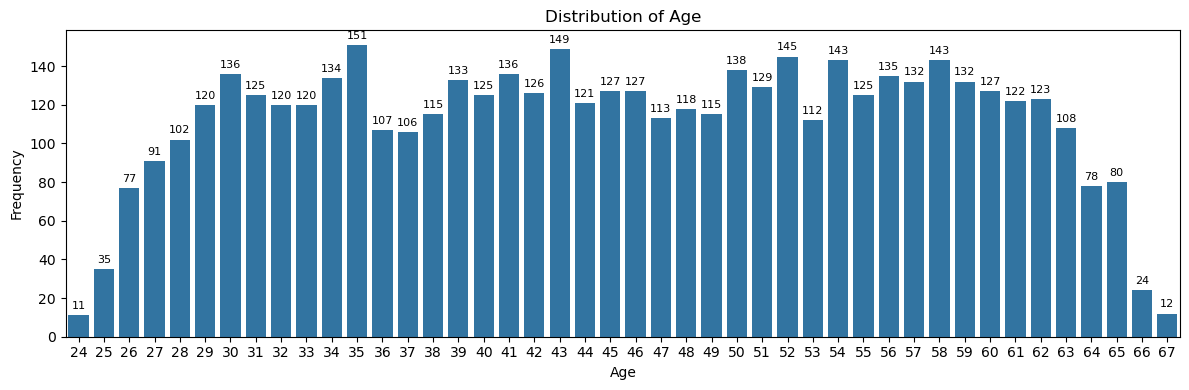

C:\Users\SarayeTell\AppData\Local\Temp\ipykernel_7172\1388198825.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2["Age_Group"] = pd.cut(


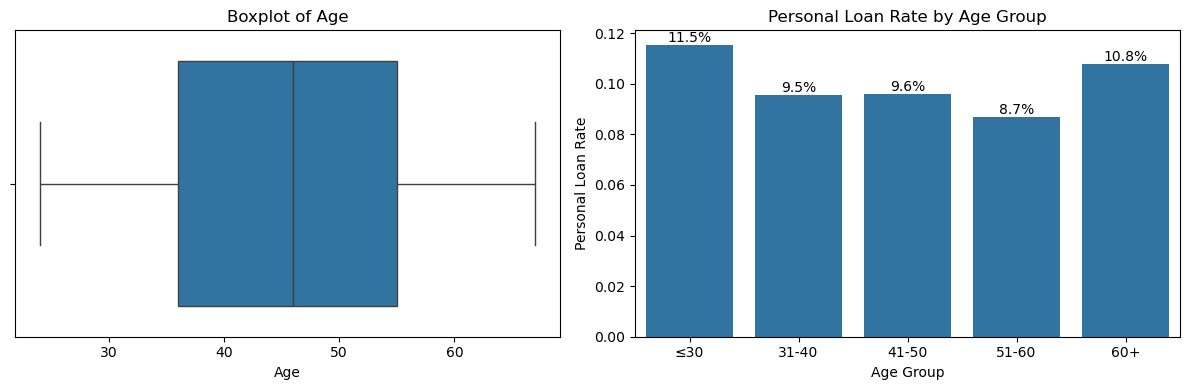

In [11]:
# 1. Distribution of Age
plt.figure(figsize=(12, 4))
ax = sns.countplot(data=data2, x="Age", order=sorted(data2["Age"].unique()))
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
# 2. Boxplot + Personal Loan Rate
data2["Age_Group"] = pd.cut(
    data2["Age"],
    bins=[0, 30, 40, 50, 60, 100],
    labels=["≤30", "31-40", "41-50", "51-60", "60+"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Boxplot
sns.boxplot(data=data2, x="Age", ax=axes[0])
axes[0].set_title("Boxplot of Age")
axes[0].set_xlabel("Age")
# Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="Age_Group",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1])
for container in ax.containers:
    labels = [f"{bar.get_height() * 100:.1f}%" for bar in container]
    ax.bar_label(container, labels=labels)
axes[1].set_title("Personal Loan Rate by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Personal Loan Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Age and Personal Loan

The **Age** variable ranges approximately from **24 to 67 years**, with most customers concentrated between **35 and 55 years**. The Boxplot shows **no significant outliers**.

The **Personal Loan** rate ranges from **8.7% to 11.5%**, with the highest rate observed among the **<30 age group (11.5%)**. There is no clear increasing or decreasing trend across age groups.

> ### 📌 Overall Conclusion
>
> **Age is well distributed with no significant outliers, but it does not show a clear relationship with Personal Loan acceptance.**


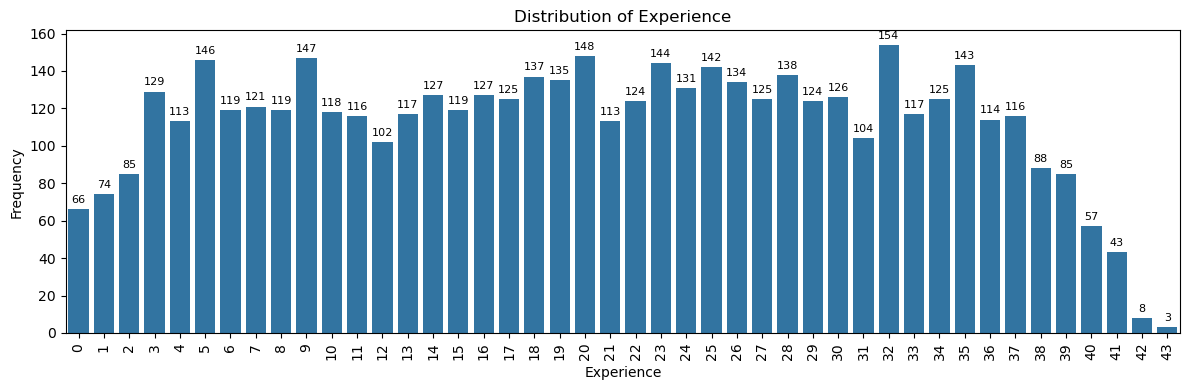

C:\Users\SarayeTell\AppData\Local\Temp\ipykernel_7172\3522191196.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2["Experience_Group"] = pd.cut(


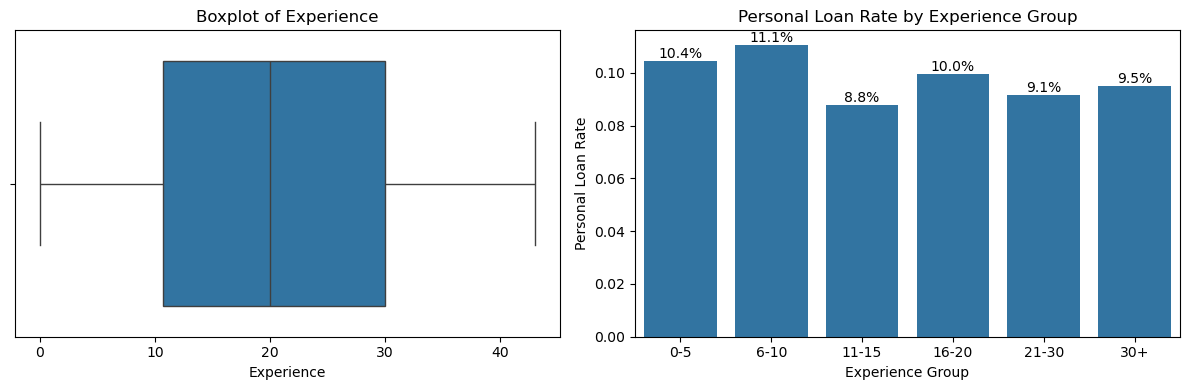

In [12]:
# 1. Distribution of Experience
plt.figure(figsize=(12, 4))
ax = sns.countplot(
    data=data2,
    x="Experience",
    order=sorted(data2["Experience"].unique()))
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)
plt.title("Distribution of Experience")
plt.xlabel("Experience")
plt.ylabel("Frequency")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
# 2. Boxplot + Personal Loan Rate
data2["Experience_Group"] = pd.cut(
    data2["Experience"],
    bins=[-1, 5, 10, 15, 20, 30, 50],
    labels=["0-5", "6-10", "11-15", "16-20", "21-30", "30+"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Boxplot
sns.boxplot(data=data2, x="Experience", ax=axes[0])
axes[0].set_title("Boxplot of Experience")
axes[0].set_xlabel("Experience")
# Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="Experience_Group",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1])
for container in ax.containers:
    labels = [f"{bar.get_height() * 100:.1f}%" for bar in container]
    ax.bar_label(container, labels=labels)
axes[1].set_title("Personal Loan Rate by Experience Group")
axes[1].set_xlabel("Experience Group")
axes[1].set_ylabel("Personal Loan Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Experience and Personal Loan

The **Experience** variable has a median of approximately **20 years**, with most values concentrated between **10 and 30 years**.

The **Personal Loan** rate varies slightly across experience groups, ranging from **8.8% to 11.1%**. The differences are small and do not show a clear trend.

> ### 📌 Overall Conclusion
>
> **Experience does not show a strong or clear relationship with Personal Loan acceptance.**


C:\Users\SarayeTell\AppData\Local\Temp\ipykernel_7172\3020092048.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2["Income_Group"] = pd.cut(


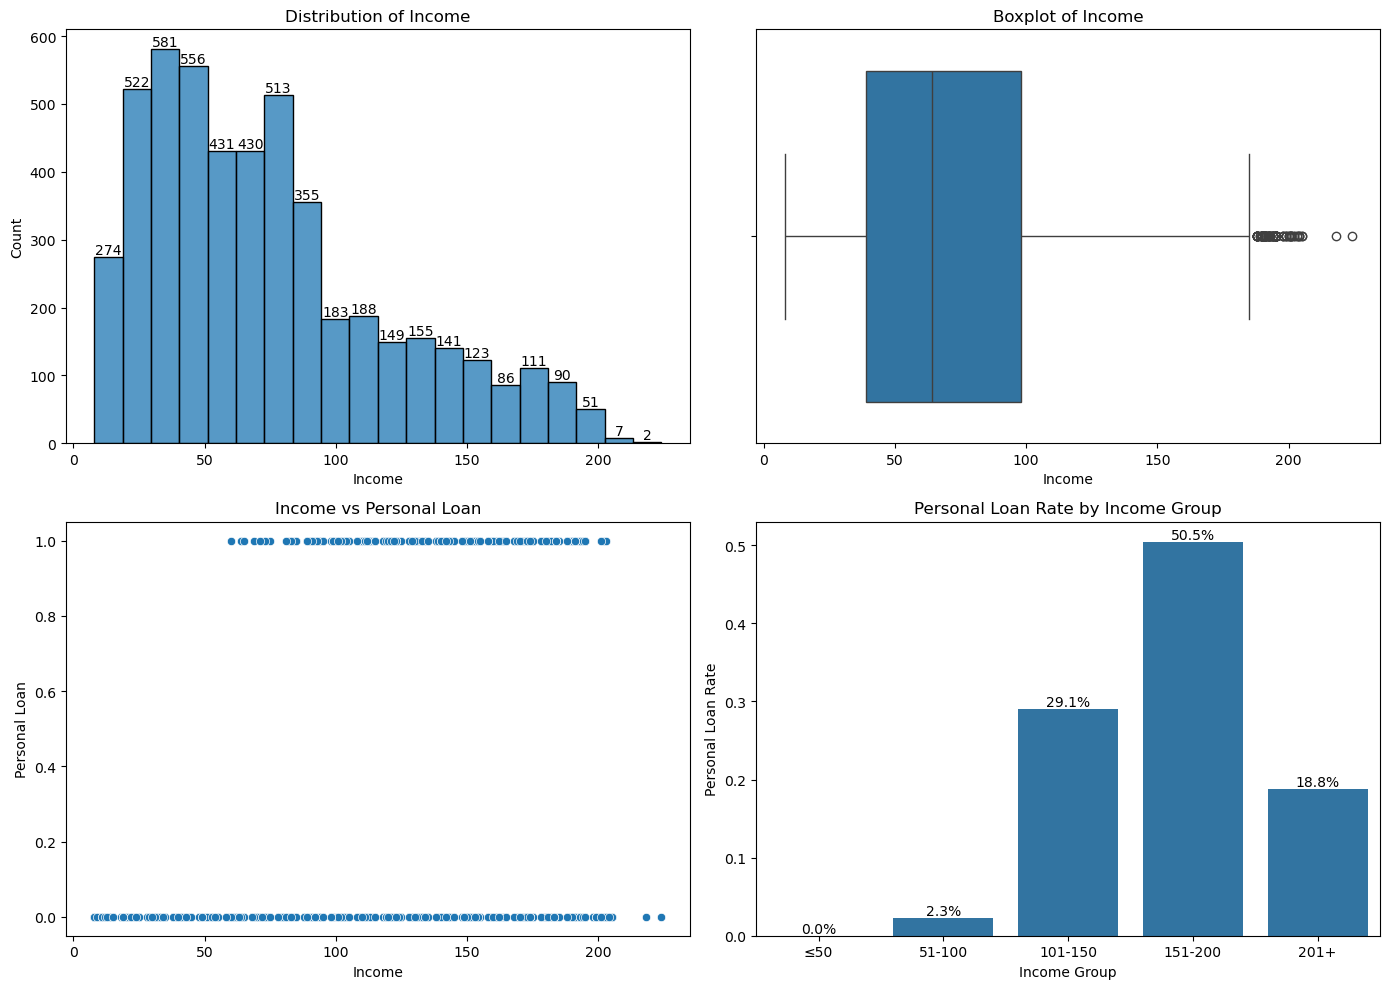

In [13]:
data2["Income_Group"] = pd.cut(
    data2["Income"],
    bins=[0, 50, 100, 150, 200, 300],
    labels=["≤50", "51-100", "101-150", "151-200", "201+"]
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
ax = sns.histplot(data=data2, x="Income", bins=20, ax=axes[0, 0])

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

axes[0, 0].set_title("Distribution of Income")
axes[0, 0].set_xlabel("Income")
axes[0, 0].set_ylabel("Count")

# 2. Boxplot
sns.boxplot(data=data2, x="Income", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of Income")
axes[0, 1].set_xlabel("Income")

# 3. Scatterplot
sns.scatterplot(
    data=data2,
    x="Income",
    y="Personal Loan",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Income vs Personal Loan")
axes[1, 0].set_xlabel("Income")
axes[1, 0].set_ylabel("Personal Loan")

# 4. Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="Income_Group",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1, 1]
)

for container in ax.containers:
    labels = [f"{bar.get_height() * 100:.1f}%" for bar in container]
    ax.bar_label(container, labels=labels)

axes[1, 1].set_title("Personal Loan Rate by Income Group")
axes[1, 1].set_xlabel("Income Group")
axes[1, 1].set_ylabel("Personal Loan Rate")

plt.tight_layout()
plt.show()

### 📊 Analysis of Income and Personal Loan

The **Income** variable ranges approximately from **8 to 224** and is **right-skewed**, with most customers having lower incomes. The Boxplot shows several high-income potential outliers, which may represent valid observations.

The **Personal Loan** acceptance rate increases noticeably with higher income levels, reaching **50.5%** in the **151–200** income group. This indicates a strong relationship between Income and Personal Loan acceptance.

> ### 📌 Overall Conclusion
>
> **Income shows a strong relationship with Personal Loan acceptance and is expected to be an important predictive feature.**


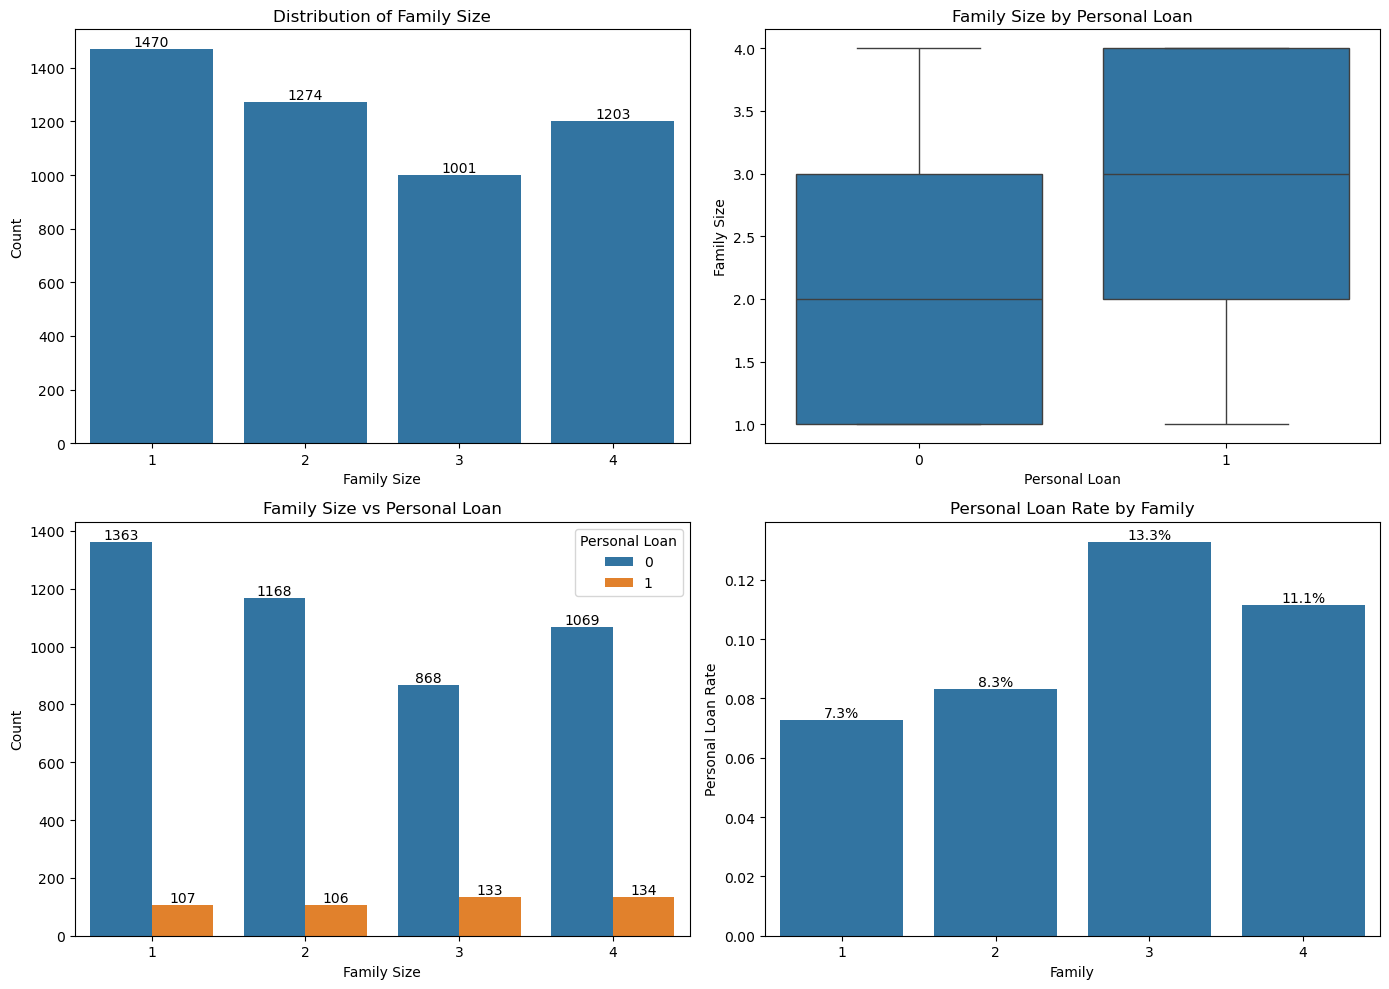

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution
ax = sns.countplot(
    data=data2,
    x="Family",
    ax=axes[0, 0]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

axes[0, 0].set_title("Distribution of Family Size")
axes[0, 0].set_xlabel("Family Size")
axes[0, 0].set_ylabel("Count")


# 2. Boxplot
sns.boxplot(
    data=data2,
    x="Personal Loan",
    y="Family",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Family Size by Personal Loan")
axes[0, 1].set_xlabel("Personal Loan")
axes[0, 1].set_ylabel("Family Size")


# 3. Family Size vs Personal Loan
ax = sns.countplot(
    data=data2,
    x="Family",
    hue="Personal Loan",
    ax=axes[1, 0]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

axes[1, 0].set_title("Family Size vs Personal Loan")
axes[1, 0].set_xlabel("Family Size")
axes[1, 0].set_ylabel("Count")


# 4. Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="Family",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1, 1]
)

for container in ax.containers:
    labels = [f"{bar.get_height() * 100:.1f}%" for bar in container]
    ax.bar_label(container, labels=labels)

axes[1, 1].set_title("Personal Loan Rate by Family")
axes[1, 1].set_xlabel("Family")
axes[1, 1].set_ylabel("Personal Loan Rate")

plt.tight_layout()
plt.show()

### 📊 Analysis of Family Size

The `Family` variable is relatively balanced across the four categories. **Family Size 1** has the highest number of customers (1472), while **Family Size 3** has the lowest (1010).

The loan rate increases from **7.3% for Family Size 1** to **13.3% for Family Size 3**, then decreases slightly to **11.1% for Family Size 4**. This indicates that customers with a **Family Size of 3** are more likely to accept a personal loan.

> ### 📌 Overall Conclusion
>
> The `Family` variable shows a **moderate relationship with Personal Loan** and may provide useful information for prediction.


C:\Users\SarayeTell\AppData\Local\Temp\ipykernel_7172\1750743979.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2["CCAvg_Group"] = pd.cut(


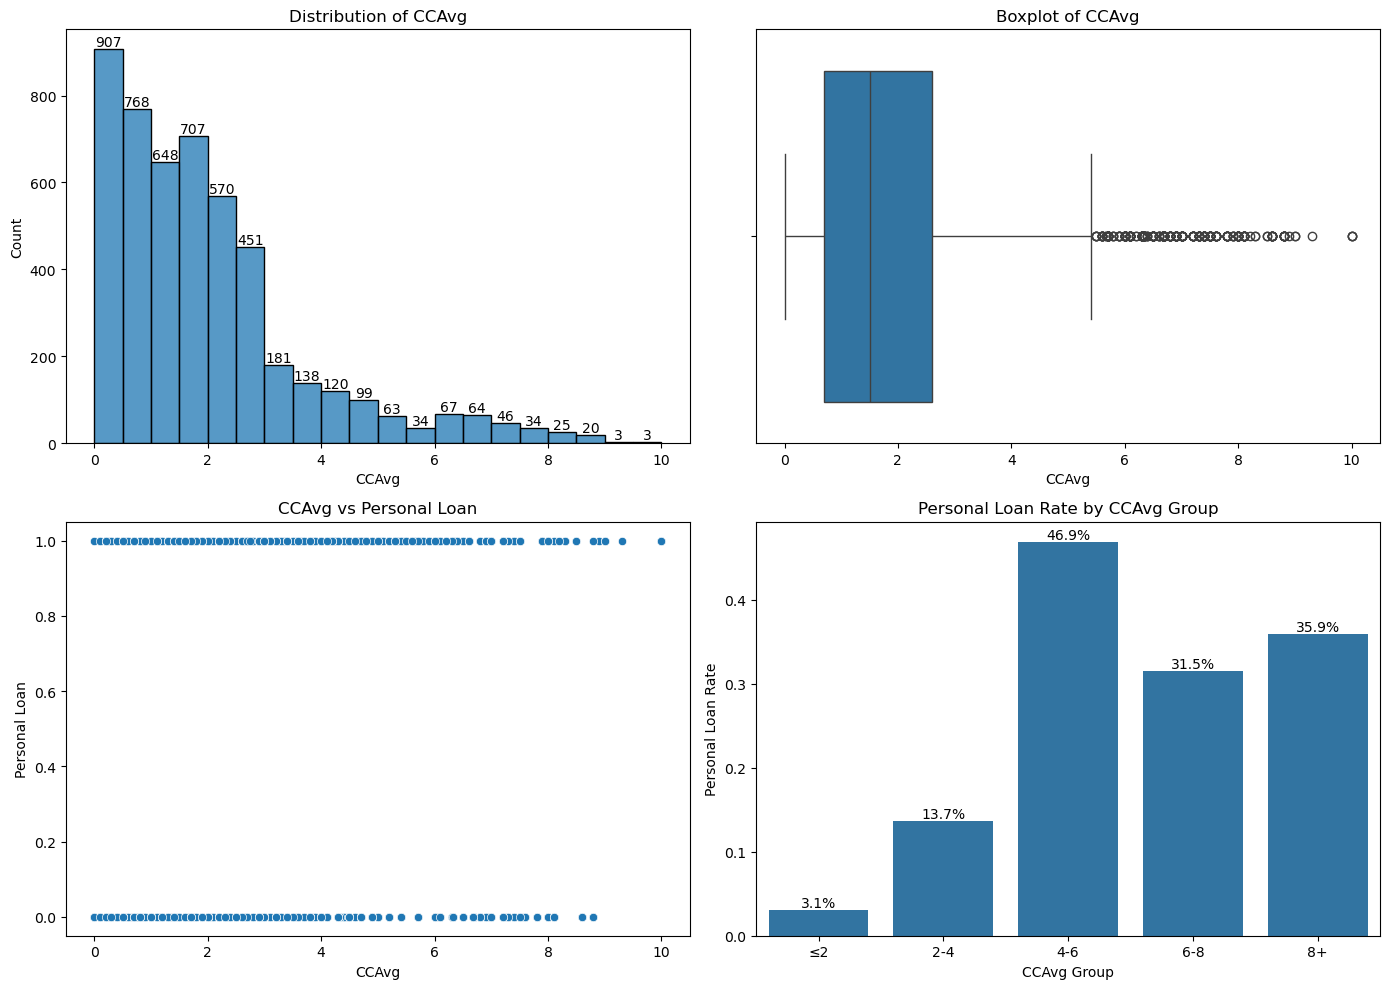

In [15]:
data2["CCAvg_Group"] = pd.cut(
    data2["CCAvg"],
    bins=[0, 2, 4, 6, 8, 12],
    labels=["≤2", "2-4", "4-6", "6-8", "8+"])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# 1. Distribution
ax = sns.histplot(
    data=data2,
    x="CCAvg",
    bins=20,
    ax=axes[0, 0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0, 0].set_title("Distribution of CCAvg")
axes[0, 0].set_xlabel("CCAvg")
axes[0, 0].set_ylabel("Count")
# 2. Boxplot
sns.boxplot(
    data=data2,
    x="CCAvg",
    ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of CCAvg")
axes[0, 1].set_xlabel("CCAvg")
# 3. CCAvg vs Personal Loan
sns.scatterplot(
    data=data2,
    x="CCAvg",
    y="Personal Loan",
    ax=axes[1, 0])
axes[1, 0].set_title("CCAvg vs Personal Loan")
axes[1, 0].set_xlabel("CCAvg")
axes[1, 0].set_ylabel("Personal Loan")
# 4. Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="CCAvg_Group",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1, 1])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[1, 1].set_title("Personal Loan Rate by CCAvg Group")
axes[1, 1].set_xlabel("CCAvg Group")
axes[1, 1].set_ylabel("Personal Loan Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of CCAvg and Personal Loan

The **CCAvg** variable is strongly **right-skewed**, with most customers having relatively low credit card spending. The boxplot also shows several **high-value outliers**.

The **Personal Loan** rate increases substantially with higher CCAvg values, rising from **3.1%** for CCAvg ≤2 to **46.9%** for the 4–6 group. The rate remains relatively high in the higher groups.

> ### 📌 Overall Conclusion
>
> **CCAvg shows a strong relationship with Personal Loan and may be an important predictive feature.**


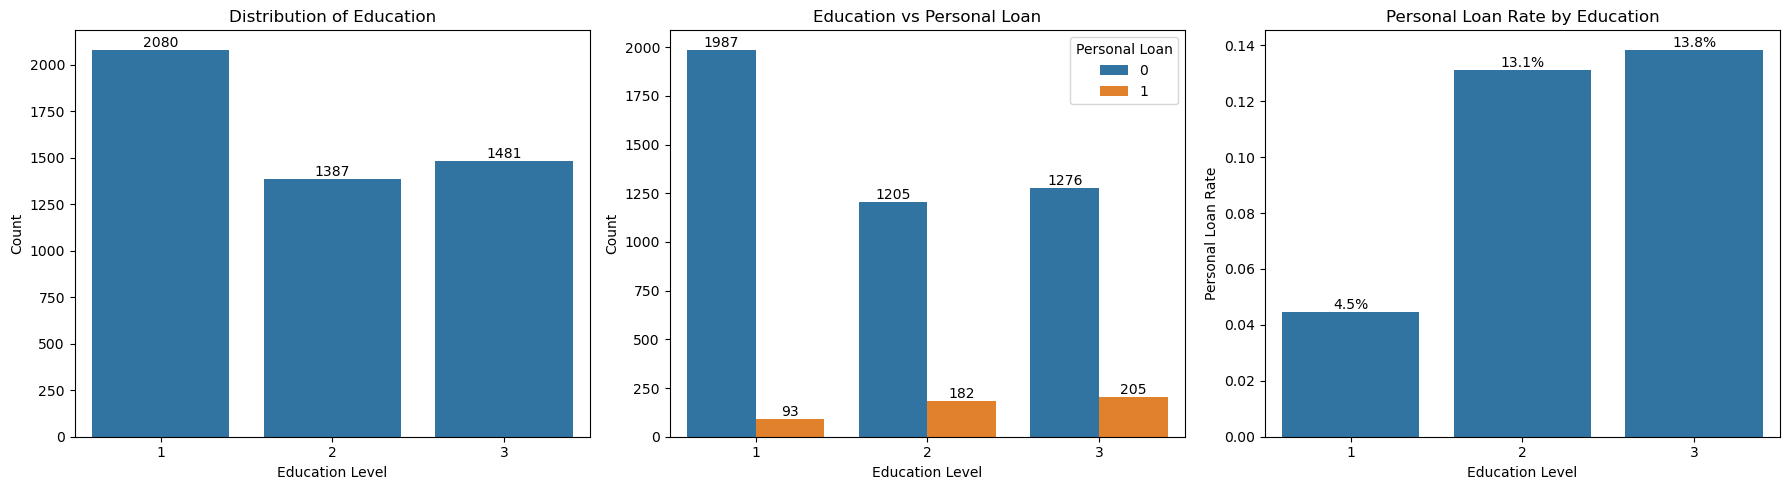

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# 1. Distribution of Education
ax = sns.countplot(
    data=data2,
    x="Education",
    ax=axes[0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0].set_title("Distribution of Education")
axes[0].set_xlabel("Education Level")
axes[0].set_ylabel("Count")
# 2. Education vs Personal Loan
ax = sns.countplot(
    data=data2,
    x="Education",
    hue="Personal Loan",
    ax=axes[1])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[1].set_title("Education vs Personal Loan")
axes[1].set_xlabel("Education Level")
axes[1].set_ylabel("Count")
# 3. Personal Loan Rate by Education
ax = sns.barplot(
    data=data2,
    x="Education",
    y="Personal Loan",
    errorbar=None,
    ax=axes[2])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[2].set_title("Personal Loan Rate by Education")
axes[2].set_xlabel("Education Level")
axes[2].set_ylabel("Personal Loan Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Education and Personal Loan

The **Education** variable has three levels, with **Level 1** having the highest number of customers (2,080), followed by **Level 3 (1,481)** and **Level 2 (1,403)**.

The **Personal Loan** rate increases from **4.5% in Level 1** to **13.1% in Level 2** and **13.8% in Level 3**. This indicates that customers with higher education levels are more likely to accept a personal loan.

> ### 📌 Overall Conclusion
>
> **Education shows a positive relationship with Personal Loan and may be a useful categorical feature for prediction.**


C:\Users\SarayeTell\AppData\Local\Temp\ipykernel_7172\418608155.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2["Mortgage_Group"] = pd.cut(


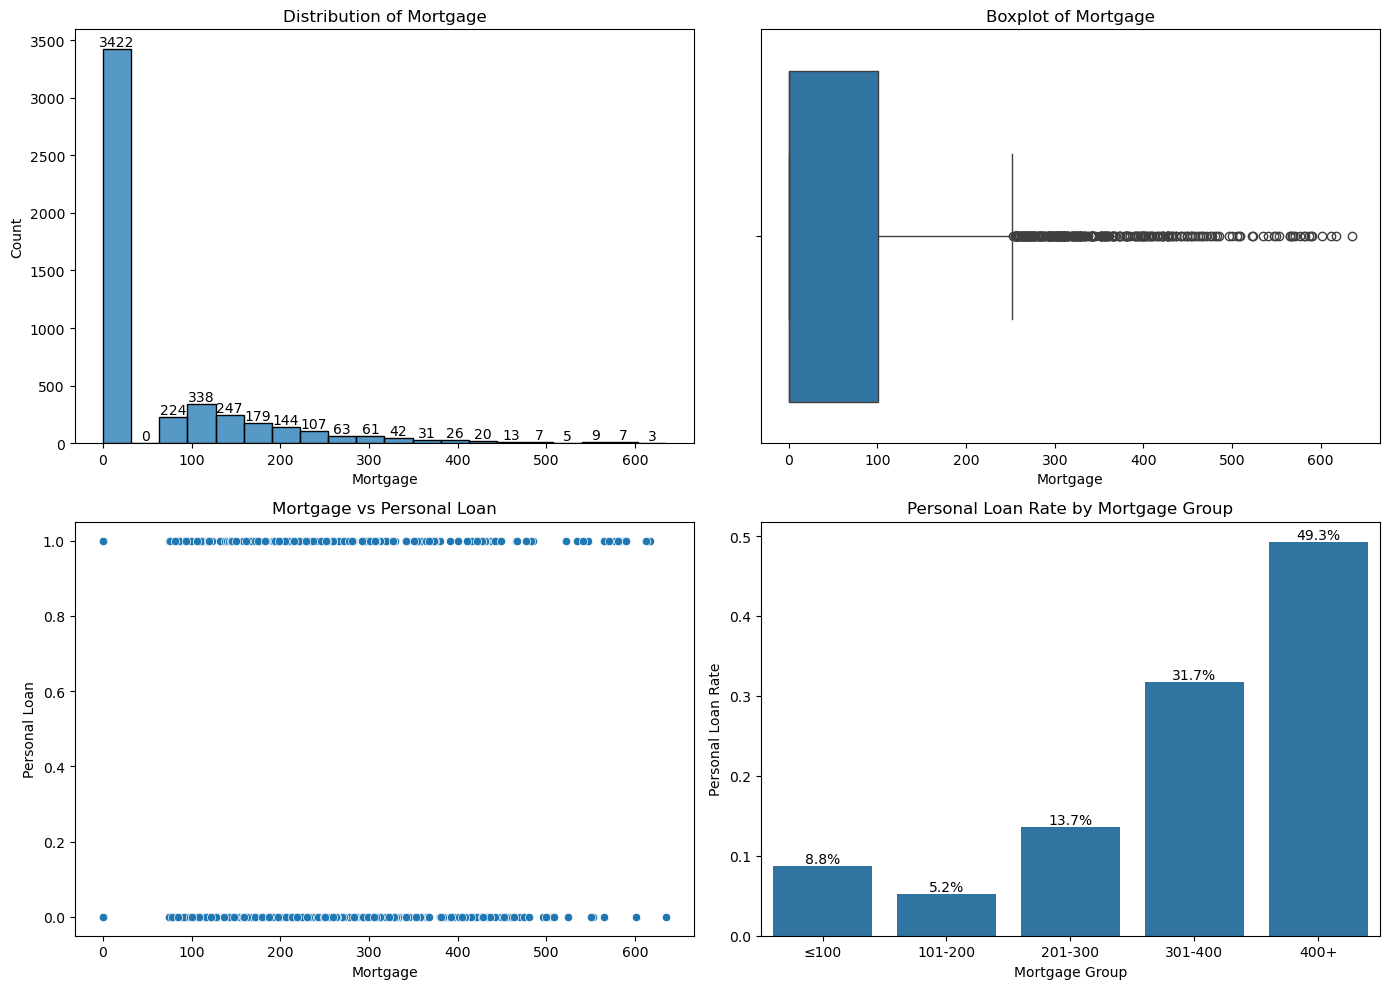

In [17]:
data2["Mortgage_Group"] = pd.cut(
    data2["Mortgage"],
    bins=[-1, 100, 200, 300, 400, 700],
    labels=["≤100", "101-200", "201-300", "301-400", "400+"])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# 1. Distribution
ax = sns.histplot(
    data=data2,
    x="Mortgage",
    bins=20,
    ax=axes[0, 0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0, 0].set_title("Distribution of Mortgage")
axes[0, 0].set_xlabel("Mortgage")
axes[0, 0].set_ylabel("Count")
# 2. Boxplot
sns.boxplot(
    data=data2,
    x="Mortgage",
    ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of Mortgage")
axes[0, 1].set_xlabel("Mortgage")
# 3. Mortgage vs Personal Loan
sns.scatterplot(
    data=data2,
    x="Mortgage",
    y="Personal Loan",
    ax=axes[1, 0])
axes[1, 0].set_title("Mortgage vs Personal Loan")
axes[1, 0].set_xlabel("Mortgage")
axes[1, 0].set_ylabel("Personal Loan")
# 4. Personal Loan Rate
ax = sns.barplot(
    data=data2,
    x="Mortgage_Group",
    y="Personal Loan",
    errorbar=None,
    ax=axes[1, 1])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[1, 1].set_title("Personal Loan Rate by Mortgage Group")
axes[1, 1].set_xlabel("Mortgage Group")
axes[1, 1].set_ylabel("Personal Loan Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Mortgage and Personal Loan

The **Mortgage** variable is highly **right-skewed**, with most customers having a mortgage value of **0**. The boxplot shows many high-value outliers, with a small number of customers having large mortgage amounts.

Customers with **Personal Loan = 1** generally have higher and more variable Mortgage values than those with `Personal Loan = 0`, suggesting a **moderate relationship** between Mortgage and Personal Loan.

> ### 📌 Overall Conclusion
>
> **Mortgage may provide useful information for predicting Personal Loan, but it is not a strong standalone predictor.**


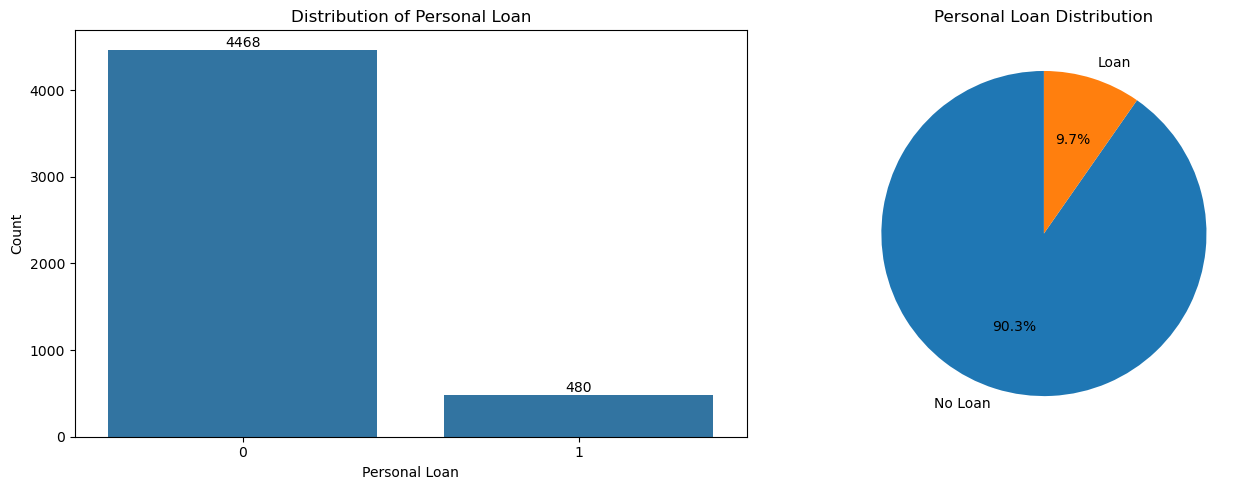

In [18]:
loan_counts = data2["Personal Loan"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# 1. Countplot
ax = sns.countplot(
    data=data2,
    x="Personal Loan",
    ax=axes[0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0].set_title("Distribution of Personal Loan")
axes[0].set_xlabel("Personal Loan")
axes[0].set_ylabel("Count")
# 2. Pie Chart
axes[1].pie(
    loan_counts,
    labels=["No Loan", "Loan"],
    autopct="%1.1f%%",
    startangle=90)
axes[1].set_title("Personal Loan Distribution")
plt.tight_layout()
plt.show()

### 📊 Analysis of Personal Loan Distribution

The dataset contains **4,948 observations**. Among them, **4,468 customers (90.3%)** belong to the **No Loan class (0)**, while **480 customers (9.7%)** belong to the **Loan class (1)**.

The **percentage breakdown** shows that the vast majority of customers did not accept a personal loan, while only **9.7%** accepted the loan offer.

This significant difference indicates a **severe class imbalance** in the target variable. Such imbalance may cause the model to become biased toward the majority class and perform poorly when identifying customers who accept a personal loan.

> ### 📌 Overall Conclusion
>
> **Personal Loan shows a severe class imbalance, with only 9.7% of observations belonging to the positive class. Therefore, appropriate techniques such as resampling or cost-sensitive methods may be necessary during predictive modeling.**


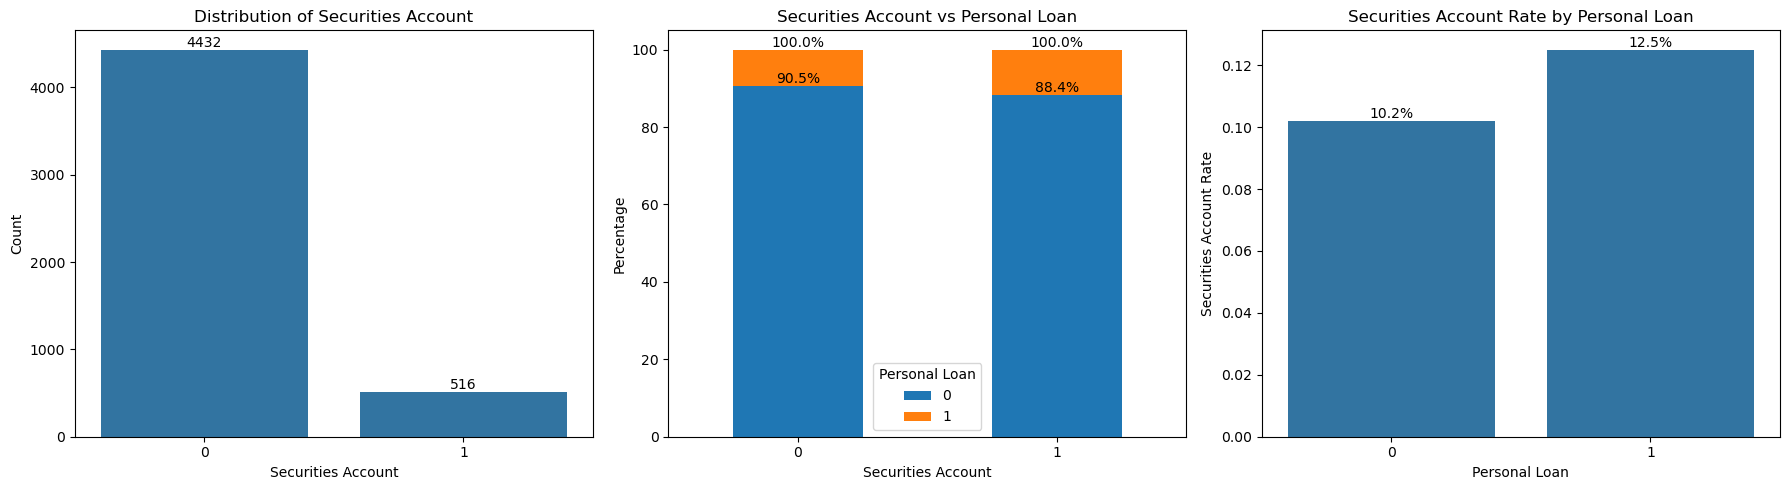

In [19]:
ct = pd.crosstab(
    data2["Securities Account"],
    data2["Personal Loan"],
    normalize="index"
) * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# 1. Distribution of Securities Account
ax = sns.countplot(
    data=data2,
    x="Securities Account",
    ax=axes[0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0].set_title("Distribution of Securities Account")
axes[0].set_xlabel("Securities Account")
axes[0].set_ylabel("Count")
# 2. Securities Account vs Personal Loan
ax = ct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
axes[1].set_title("Securities Account vs Personal Loan")
axes[1].set_xlabel("Securities Account")
axes[1].set_ylabel("Percentage")
axes[1].legend(title="Personal Loan")
axes[1].set_xticklabels(["0", "1"], rotation=0)
# 3. Securities Account Rate by Personal Loan
ax = sns.barplot(
    data=data2,
    x="Personal Loan",
    y="Securities Account",
    errorbar=None,
    ax=axes[2])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[2].set_title("Securities Account Rate by Personal Loan")
axes[2].set_xlabel("Personal Loan")
axes[2].set_ylabel("Securities Account Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Securities Account and Personal Loan

The **Securities Account** variable has two levels. **Level 0** includes **4,432 customers**, while **Level 1** includes only **516 customers**.

The Securities Account rate increases slightly from **10.2%** among non-loan holders to **12.5%** among loan holders. This suggests that customers who accept a personal loan are slightly more likely to hold a securities account.

> ### 📌 Overall Conclusion
>
> **Securities Account shows a weak positive relationship with Personal Loan and may have limited predictive power.**


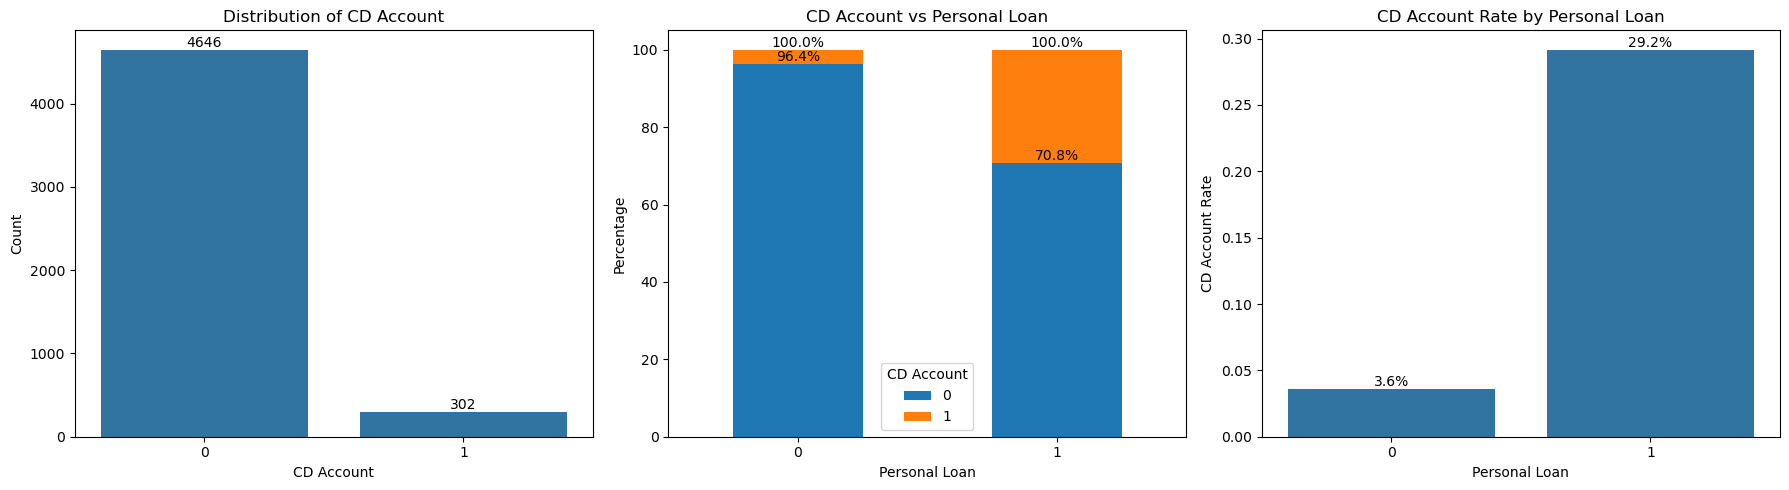

In [20]:
ct = pd.crosstab(
    data2["Personal Loan"],
    data2["CD Account"],
    normalize="index"
) * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# 1. Distribution of CD Account
ax = sns.countplot(
    data=data2,
    x="CD Account",
    ax=axes[0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0].set_title("Distribution of CD Account")
axes[0].set_xlabel("CD Account")
axes[0].set_ylabel("Count")
# 2. CD Account vs Personal Loan
ax = ct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
axes[1].set_title("CD Account vs Personal Loan")
axes[1].set_xlabel("Personal Loan")
axes[1].set_ylabel("Percentage")
axes[1].set_xticklabels(["0", "1"], rotation=0)
axes[1].legend(title="CD Account")
# 3. CD Account Rate by Personal Loan
ax = sns.barplot(
    data=data2,
    x="Personal Loan",
    y="CD Account",
    errorbar=None,
    ax=axes[2])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[2].set_title("CD Account Rate by Personal Loan")
axes[2].set_xlabel("Personal Loan")
axes[2].set_ylabel("CD Account Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of CD Account and Personal Loan

The **CD Account** variable has two levels. **Level 0** includes **4,698 customers**, while **Level 1** includes only **302 customers**.

The CD Account rate increases significantly from **3.6%** among non-loan holders to **29.2%** among loan holders. This indicates that customers who accept a personal loan are substantially more likely to hold a CD account.

> ### 📌 Overall Conclusion
>
> **CD Account shows a strong positive relationship with Personal Loan and is likely to be an important categorical feature for prediction.**


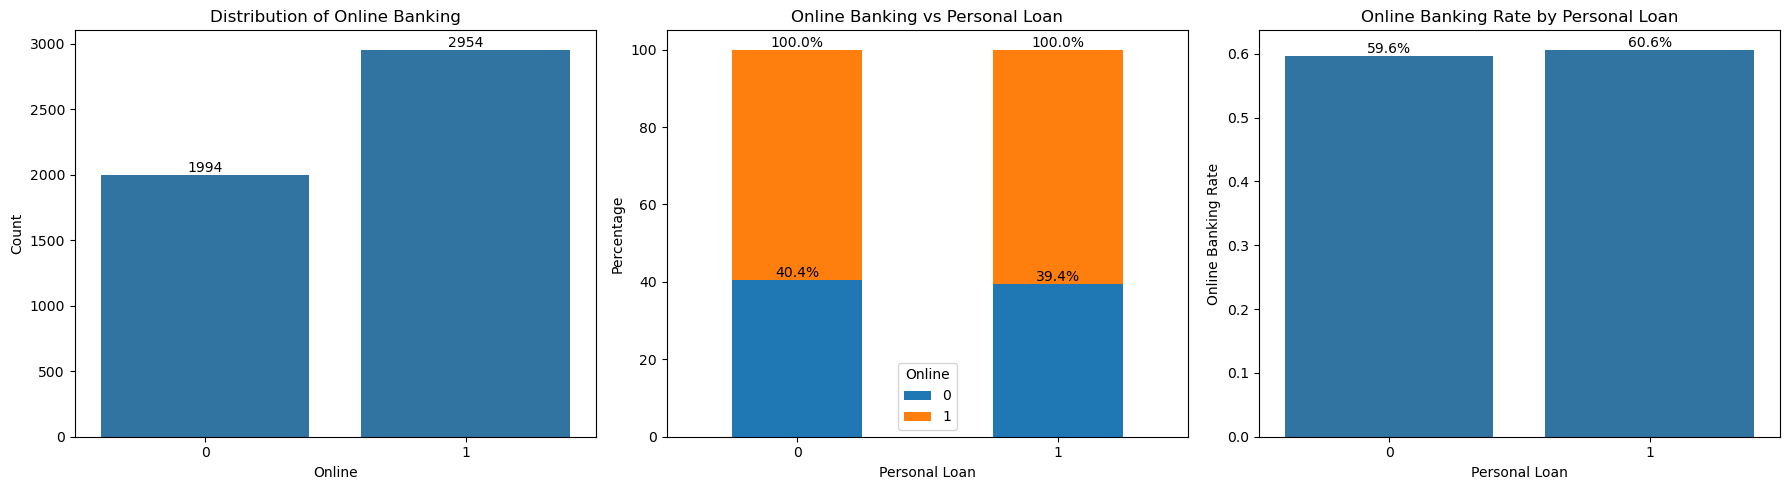

In [21]:
ct = pd.crosstab(
    data2["Personal Loan"],
    data2["Online"],
    normalize="index"
) * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# 1. Distribution of Online Banking
ax = sns.countplot(
    data=data2,
    x="Online",
    ax=axes[0])
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
axes[0].set_title("Distribution of Online Banking")
axes[0].set_xlabel("Online")
axes[0].set_ylabel("Count")
# 2. Online Banking vs Personal Loan
ax = ct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
axes[1].set_title("Online Banking vs Personal Loan")
axes[1].set_xlabel("Personal Loan")
axes[1].set_ylabel("Percentage")
axes[1].set_xticklabels(["0", "1"], rotation=0)
axes[1].legend(title="Online")
# 3. Online Banking Rate by Personal Loan
ax = sns.barplot(
    data=data2,
    x="Personal Loan",
    y="Online",
    errorbar=None,
    ax=axes[2])
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)
axes[2].set_title("Online Banking Rate by Personal Loan")
axes[2].set_xlabel("Personal Loan")
axes[2].set_ylabel("Online Banking Rate")
plt.tight_layout()
plt.show()

### 📊 Analysis of Online Banking and Personal Loan

The **Online Banking** variable has two levels. **Level 1** includes **2,954 customers**, while **Level 0** includes **1,994 customers**.

The Online Banking rate remains almost unchanged, increasing slightly from **59.6%** among non-loan holders to **60.6%** among loan holders. This indicates that Online Banking has little effect on the likelihood of accepting a personal loan.

> ### 📌 Overall Conclusion
>
> **Online Banking shows virtually no relationship with Personal Loan and has negligible predictive power.**


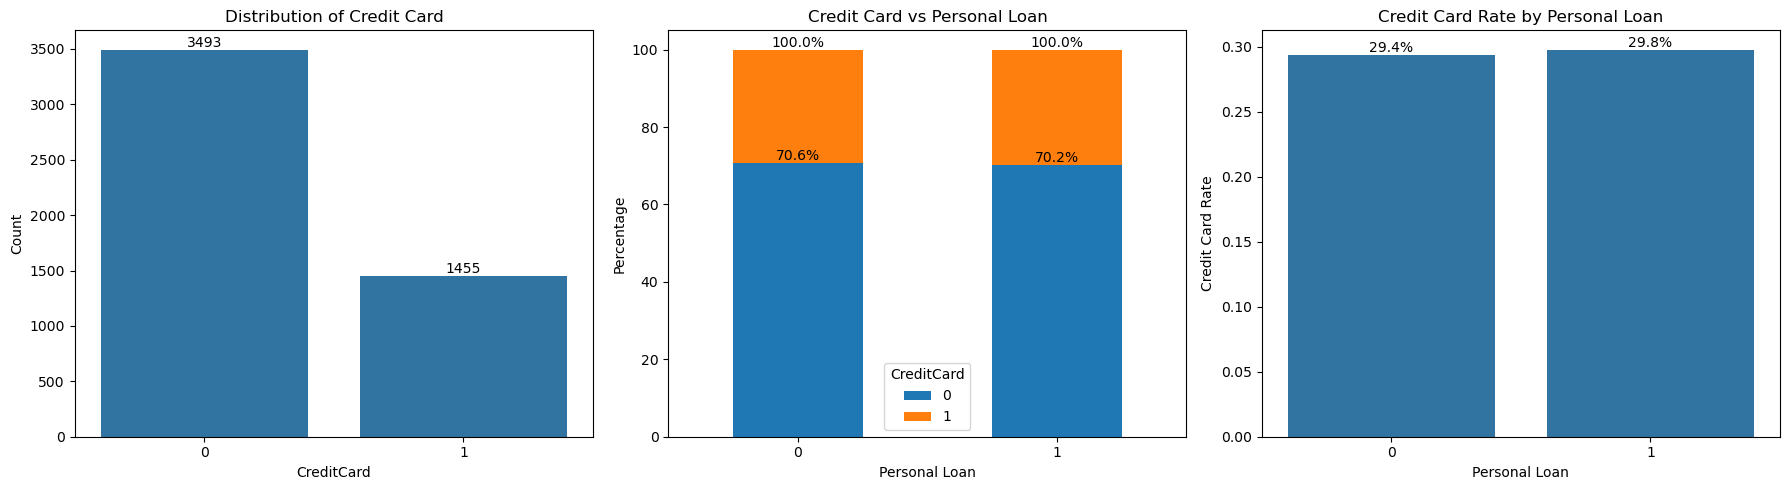

In [22]:
ct = pd.crosstab(
    data2["Personal Loan"],
    data2["CreditCard"],
    normalize="index"
) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of Credit Card
ax = sns.countplot(
    data=data2,
    x="CreditCard",
    ax=axes[0]
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

axes[0].set_title("Distribution of Credit Card")
axes[0].set_xlabel("CreditCard")
axes[0].set_ylabel("Count")


# 2. Credit Card vs Personal Loan
ax = ct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1]
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

axes[1].set_title("Credit Card vs Personal Loan")
axes[1].set_xlabel("Personal Loan")
axes[1].set_ylabel("Percentage")
axes[1].set_xticklabels(["0", "1"], rotation=0)
axes[1].legend(title="CreditCard")


# 3. Credit Card Rate by Personal Loan
ax = sns.barplot(
    data=data2,
    x="Personal Loan",
    y="CreditCard",
    errorbar=None,
    ax=axes[2]
)
for container in ax.containers:
    labels = [
        f"{bar.get_height() * 100:.1f}%"
        for bar in container
    ]
    ax.bar_label(container, labels=labels)

axes[2].set_title("Credit Card Rate by Personal Loan")
axes[2].set_xlabel("Personal Loan")
axes[2].set_ylabel("Credit Card Rate")

plt.tight_layout()
plt.show()

### 📊 Analysis of Credit Card and Personal Loan

The **Credit Card** variable has two levels, with **Level 0** having the highest number of customers (**3,493**), while **Level 1** consists of **1,455** customers.

The Credit Card rate remains almost identical, changing slightly from **29.4%** among non-loan holders to **29.8%** among loan holders. This indicates that holding a credit card has virtually no impact on the likelihood of accepting a personal loan.

> ### 📌 Overall Conclusion
>
> **Credit Card shows virtually no relationship with Personal Loan and has negligible predictive power for the model.**


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Outlier and Noise Analysis
</h2>

<p style="font-size:16px; line-height:1.8;">

The <b>Income</b>, <b>CCAvg</b>, and <b>Mortgage</b> features contain outlier values. 
However, these outliers are <b>not removed</b> because they may represent real customer characteristics rather than incorrect or noisy data.

</p>

<p style="font-size:16px; line-height:1.8;">

Therefore, these values are retained to preserve potentially useful information for the machine learning model.

</p>

</div>



<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Correlation Analysis
</h2>

<p style="font-size:16px; line-height:1.8;">

Correlation analysis is used to examine the strength and direction of relationships between numerical features. 
In this analysis, the <b>Spearman correlation</b> method is used to identify positive, negative, and weak or strong relationships between the features and the target variable. 
This analysis can also help detect highly correlated features and possible <b>multicollinearity</b> before building the machine learning model.

</p>

</div>

<Axes: >

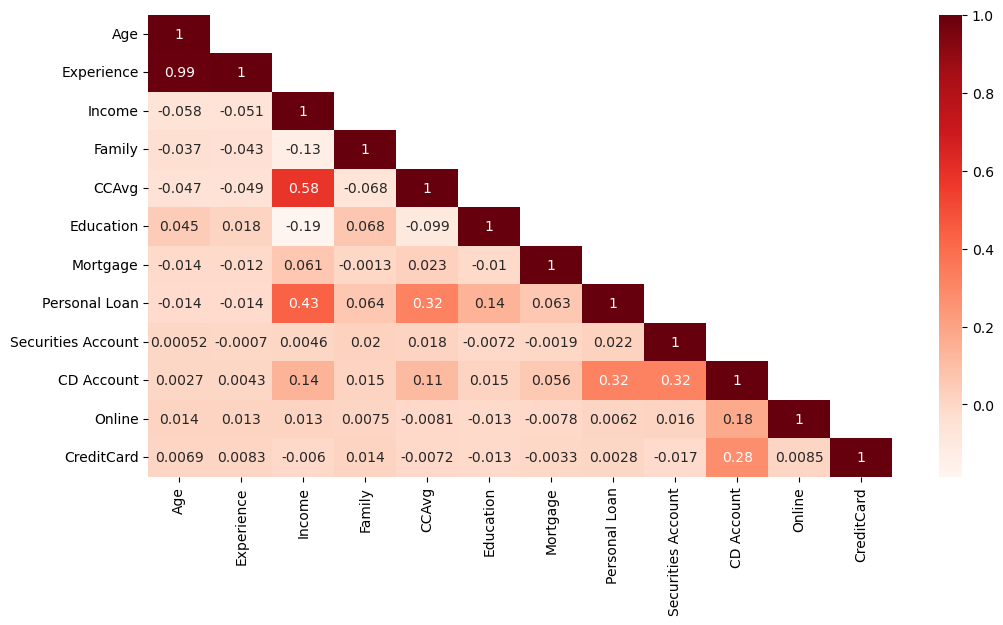

In [23]:
numeric_data=data2.select_dtypes(include=["number"])
corr=numeric_data.corr(method="spearman")
fig,ax=plt.subplots(figsize=(12,6))
mask=np.zeros_like(corr)
mask[np.triu_indices_from(mask,1)]=True
sns.heatmap(corr,cmap="Reds",mask=mask,annot=True,ax=ax)

# Correlation Analysis

The correlation analysis was used to examine the relationships between the numerical features.

* **Age:** Age has an extremely strong positive correlation with **Experience (0.994)**, while its correlations with the other features are very weak or close to zero.
* **Experience:** Experience shows the same pattern, with its strongest relationship being with **Age (0.994)**. Its relationship with Personal Loan is almost zero.
* **Income:** Income has a moderate positive correlation with **CCAvg (0.580)** and **Personal Loan (0.431)**. It also has weak negative relationships with Education and Family.
* **Family:** Family has only weak relationships with other features, with its strongest correlation being with Income (**-0.133**).
* **CCAvg:** CCAvg has a moderate positive correlation with Income (**0.580**) and a weak positive correlation with Personal Loan (**0.314**).
* **Education:** Education has a weak negative correlation with Income (**-0.183**) and a weak positive correlation with Personal Loan (**0.139**).
* **Mortgage:** Mortgage has very weak correlations with all features, including Personal Loan (**0.063**).
* **Securities Account:** It has very weak correlations with most variables. Its strongest relationship is with CD Account (**0.317**).
* **CD Account:** CD Account has weak positive correlations with Securities Account (**0.317**), Personal Loan (**0.316**), and CreditCard (**0.279**).
* **Online:** Online has very weak correlations with all variables, including Personal Loan (**0.006**).
* **CreditCard:** CreditCard has weak correlation with CD Account (**0.279**) but almost no correlation with Personal Loan (**0.003**).

## Conclusion

The strongest correlation in the dataset is between **Age and Experience (0.994)**, indicating severe redundancy and possible multicollinearity. Therefore, one of these two features should be removed. In this analysis, **Experience is removed and Age is retained**, as both features have almost the same relationship with the target variable, while Experience is retained as the more directly relevant professional-background feature.

The features with the strongest relationships with the target are **Income (0.431), CD Account (0.316), and CCAvg (0.314)**, so they should be retained for further modeling.

Overall, **Experience is the main candidates for removal**, while the remaining features should be evaluated further using methods such as **VIF and model-based feature selection**.


In [24]:
data3=data2.drop(columns=["Experience","Age_Group", "Experience_Group","Income_Group","CCAvg_Group","Mortgage_Group"])
data3

,Age,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,49,4,1.6,1,0,0,1,0,0,0
1,45,34,3,1.5,1,0,0,1,0,0,0
2,39,11,1,1.0,1,0,0,0,0,0,0
3,35,100,1,2.7,2,0,0,0,0,0,0
4,35,45,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,29,40,1,1.9,3,0,0,0,0,1,0
4996,30,15,4,0.4,1,85,0,0,0,1,0
4997,63,24,2,0.3,3,0,0,0,0,0,0
4998,65,49,3,0.5,2,0,0,0,0,1,0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🗑️ Deleting Duplicated Samples
</h2>

<p style="font-size:16px; line-height:1.8;">

Duplicated samples are removed to ensure that each observation appears only once in the dataset. 
This step helps prevent repeated records from affecting the analysis and improves the quality and reliability of the machine learning model.

</p>

</div>

In [25]:
duplicates=data3.sum()

In [26]:
data4=data3.drop_duplicates()
print(data3.duplicated().sum())

13


In [27]:
print("Before:", data3.shape)
print("Duplicates:", data3.duplicated().sum())
data4 = data3.drop_duplicates()
print("After:", data4.shape)
print("Duplicates after:", data4.duplicated().sum())

Before: (4948, 11)
Duplicates: 13
After: (4935, 11)
Duplicates after: 0


<div style="
background-color:#9fb8d2;
padding:12px 20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h3 style="color:#1565C0; margin:0;">
✨ Final and Clean Data up here
</h3>

</div>

In [28]:
data4

,Age,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,49,4,1.6,1,0,0,1,0,0,0
1,45,34,3,1.5,1,0,0,1,0,0,0
2,39,11,1,1.0,1,0,0,0,0,0,0
3,35,100,1,2.7,2,0,0,0,0,0,0
4,35,45,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,29,40,1,1.9,3,0,0,0,0,1,0
4996,30,15,4,0.4,1,85,0,0,0,1,0
4997,63,24,2,0.3,3,0,0,0,0,0,0
4998,65,49,3,0.5,2,0,0,0,0,1,0


In [29]:
data4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4935 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 4935 non-null   int64  
 1   Income              4935 non-null   int64  
 2   Family              4935 non-null   int64  
 3   CCAvg               4935 non-null   float64
 4   Education           4935 non-null   int64  
 5   Mortgage            4935 non-null   int64  
 6   Personal Loan       4935 non-null   int64  
 7   Securities Account  4935 non-null   int64  
 8   CD Account          4935 non-null   int64  
 9   Online              4935 non-null   int64  
 10  CreditCard          4935 non-null   int64  
dtypes: float64(1), int64(10)
memory usage: 462.7 KB


In [30]:
data4.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4935.0,45.567173,11.317788,24.0,36.0,46.0,55.0,67.0
Income,4935.0,73.865451,46.142012,8.0,39.0,64.0,98.0,224.0
Family,4935.0,2.391692,1.148293,1.0,1.0,2.0,3.0,4.0
CCAvg,4935.0,1.938640,1.748875,0.0,0.7,1.5,2.6,10.0
Education,4935.0,1.877204,0.839536,1.0,1.0,2.0,3.0,3.0
Mortgage,4935.0,56.783587,101.921386,0.0,0.0,0.0,101.5,635.0
Personal Loan,4935.0,0.097264,0.296348,0.0,0.0,0.0,0.0,1.0
Securities Account,4935.0,0.104559,0.306016,0.0,0.0,0.0,0.0,1.0
CD Account,4935.0,0.061196,0.239713,0.0,0.0,0.0,0.0,1.0
Online,4935.0,0.596353,0.490678,0.0,0.0,1.0,1.0,1.0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating KNN Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, a
<b>K-Nearest Neighbors (KNN) Classifier</b> is built to predict whether a customer is likely to accept a
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

The KNN algorithm classifies a customer based on the classes of its
<b>K nearest neighbors</b> in the feature space. It calculates the distance between data points
and assigns a class based on the majority vote of the nearest neighbors.

</p>

<p style="font-size:16px; line-height:1.8;">

Different values of <b>K</b> can be tested to find a suitable model configuration.
The model is then evaluated using metrics such as <b>Accuracy, Precision, Recall, and F1-Score</b>
to measure how effectively it identifies customers who are likely to accept a personal loan.

</p>

</div>

In [31]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [32]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [33]:
scaler=StandardScaler()
scaler.fit(x_train)
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [34]:
KNN_Model=KNeighborsClassifier(n_neighbors=3)
KNN_Model.fit(x_train_scaled,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [35]:
y_pred=KNN_Model.predict(x_test_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
⚙️ Tuning Hyperparameters
</h2>

<p style="font-size:16px; line-height:1.8;">

After creating the KNN model, the next step is to perform 
<b>hyperparameter tuning</b> to find the most suitable value of 
<b>K (n_neighbors)</b> for the model.

</p>

<p style="font-size:16px; line-height:1.8;">

Different values of <b>K</b>, ranging from <b>1 to 31</b>, are tested 
and evaluated using performance metrics such as 
<b>Accuracy, Precision, Recall, and F1-Score</b>.
This process helps determine which value of K provides the best model performance.

</p>

<p style="font-size:16px; line-height:1.8;">

The best value of <b>K</b> is selected based on the model's performance 
and its ability to generalize well to unseen data. This helps reduce the risk 
of <b>overfitting or underfitting</b> and improves the reliability of the final model.

</p>

</div>

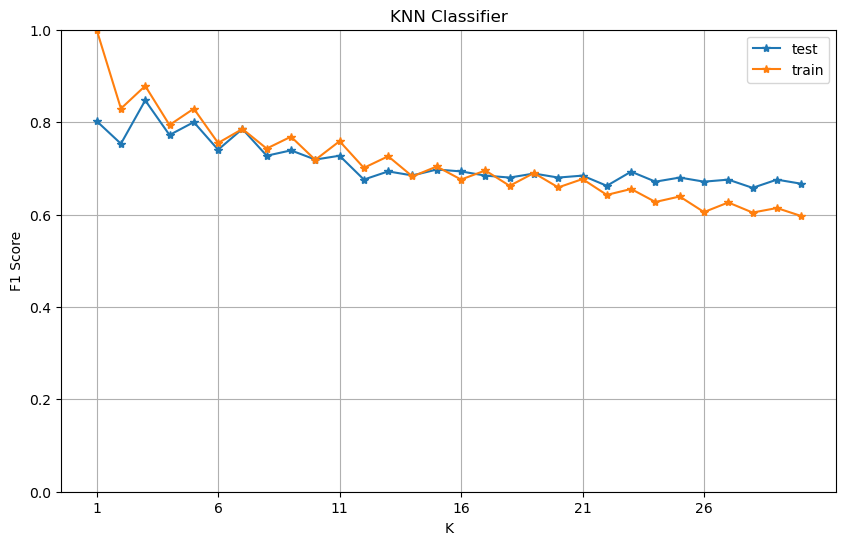

In [36]:
K = range(1, 31)
train_f1 = []
test_f1 = []
for k in K:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train_scaled, y_train)
    train_pred = knn.predict(x_train_scaled)
    train_f1.append(f1_score(y_train, train_pred))
    test_pred = knn.predict(x_test_scaled)
    test_f1.append(f1_score(y_test, test_pred))
    
plt.figure(figsize=(10, 6))
plt.plot(K, test_f1, marker='*', label='test')
plt.plot(K, train_f1, marker='*', label='train')
plt.xlabel('K')
plt.ylabel('F1 Score')
plt.title('KNN Classifier')
plt.xticks(range(1, 31, 5))
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

<div style="background-color:#9fb8d2; padding:20px; border-radius:12px; border-left:8px solid #7e93ba;">

<h2 style="color:#1565C0; margin-bottom:15px;">🔧 KNN Model Tuning</h2>

<p style="font-size:16px; line-height:1.8; color:#263238;">
Based on the <b>K vs F1-Score</b> plot, <b>n_neighbors = 3</b> is selected for tuning the KNN model.
</p>

</div>

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [37]:
def model_evaluation(x_train_scaled, x_test_scaled, y_train, y_test, KNN_Model):

    # Predictions
    y_train_pred = KNN_Model.predict(x_train_scaled)
    y_test_pred = KNN_Model.predict(x_test_scaled)

    # Probability predictions for ROC Curve
    y_train_prob = KNN_Model.predict_proba(x_train_scaled)[:, 1]
    y_test_prob = KNN_Model.predict_proba(x_test_scaled)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

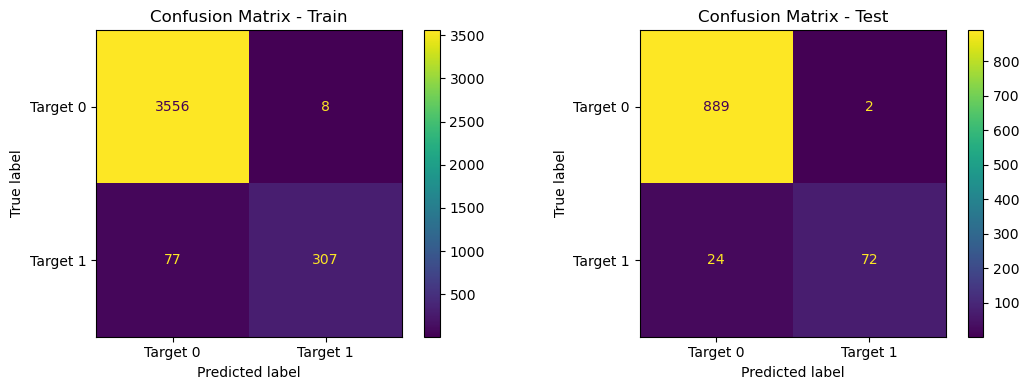

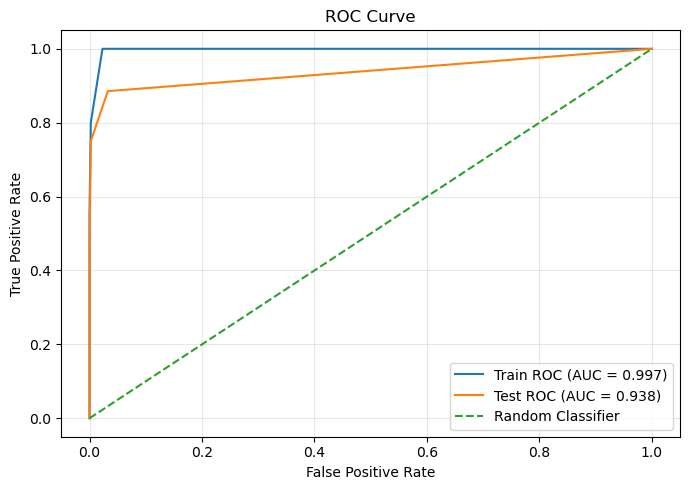

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.978470,0.974603,0.799479,0.878398,0.997191
1,Test,891,96,0.973658,0.972973,0.750000,0.847059,0.938149


In [38]:
results = model_evaluation(
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test,
    KNN_Model
)

results



<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [39]:
def drop_column_plot(KNN_Model, x_train_scaled, y_train, x_test_scaled, y_test, feature_names):

    results = []

    y_test_pred = KNN_Model.predict(x_test_scaled)

    base_f1 = f1_score(y_test, y_test_pred)

    best_k = KNN_Model.n_neighbors

    x_train_df = pd.DataFrame(
        x_train_scaled,
        columns=feature_names
    )

    x_test_df = pd.DataFrame(
        x_test_scaled,
        columns=feature_names
    )

    for column in feature_names:

        x_train_scaled_drop = x_train_df.drop(
            columns=[column]
        ).values

        x_test_scaled_drop = x_test_df.drop(
            columns=[column]
        ).values

        model_drop = KNeighborsClassifier(
            n_neighbors=best_k
        )

        model_drop.fit(
            x_train_scaled_drop,
            y_train
        )

        y_test_pred_drop = model_drop.predict(
            x_test_scaled_drop
        )

        f1_drop = f1_score(
            y_test,
            y_test_pred_drop
        )

        importance = base_f1 - f1_drop

        results.append({
            'Feature': column,
            'Importance': importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=True
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        importance_df['Feature'],
        importance_df['Importance']
    )

    plt.axvline(
        x=0,
        linestyle='--'
    )

    plt.xlabel('F1 Score Importance')

    plt.ylabel('Feature')

    plt.title('Drop Column Feature Importance - KNN')

    plt.tight_layout()

    plt.show()

    return importance_df

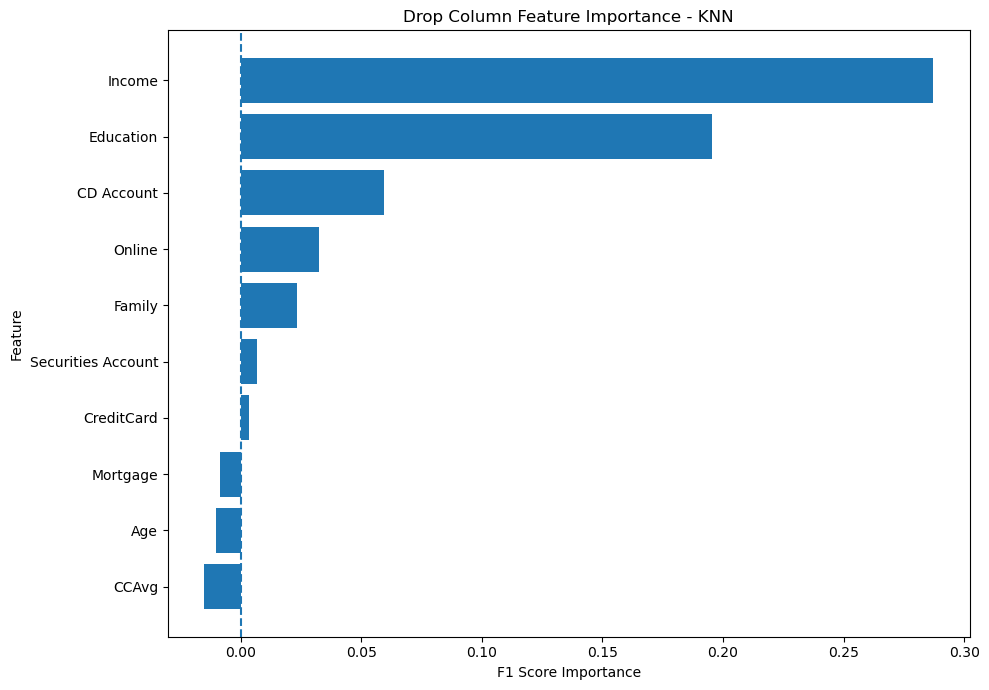

,Feature,Importance
3,CCAvg,-0.015010
0,Age,-0.010084
5,Mortgage,-0.008433
9,CreditCard,0.003685
6,Securities Account,0.006822
2,Family,0.023529
8,Online,0.032688
7,CD Account,0.059559
4,Education,0.195373
1,Income,0.287059


In [40]:
feature_names = x.columns.tolist()

drop_importance = drop_column_plot(
    KNN_Model,
    x_train_scaled,
    y_train,
    x_test_scaled,
    y_test,
    feature_names
)

drop_importance

In [41]:
data5=data4.drop(columns=["CCAvg","Mortgage","Age"])
data5

,Income,Family,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,49,4,1,0,1,0,0,0
1,34,3,1,0,1,0,0,0
2,11,1,1,0,0,0,0,0
3,100,1,2,0,0,0,0,0
4,45,4,2,0,0,0,0,1
...,...,...,...,...,...,...,...,...
4995,40,1,3,0,0,0,1,0
4996,15,4,1,0,0,0,1,0
4997,24,2,3,0,0,0,0,0
4998,49,3,2,0,0,0,1,0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating Model After Drop Column Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">
After evaluating the features using <b>Drop Column Feature Importance</b>,
the importance of each feature was determined based on its effect on the
<b>F1 Score</b>. Features with a higher importance had a greater contribution
to the model's predictive performance.
</p>

<p style="font-size:16px; line-height:1.8;">
Based on the results, the less important features can be removed from the
dataset, and the KNN model can then be trained again using the remaining
features. This helps create a simpler model while maintaining the most
important information for predicting <b>Personal Loan</b>.
</p>

<p style="font-size:16px; line-height:1.8;">
After dropping the selected features, the model was recreated and evaluated
again using the <b>F1 Score</b> to determine whether the reduced feature set
improved or maintained the model's performance.
</p>

</div>

In [42]:
x=data5.drop("Personal Loan",axis=1)
y=data5["Personal Loan"]

In [43]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [44]:
scaler=StandardScaler()
scaler.fit(x_train)
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [45]:
KNN_Model_drop=KNeighborsClassifier(n_neighbors=3)
KNN_Model_drop.fit(x_train_scaled,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [46]:
y_pred=KNN_Model_drop.predict(x_test_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">
After creating the model, its performance was evaluated on both the
<b>Training</b> and <b>Testing</b> datasets. Several evaluation metrics,
including <b>Accuracy, Precision, Recall, and F1 Score</b>, were used to
measure the performance of the KNN model.
</p>

<p style="font-size:16px; line-height:1.8;">
Since the <b>Personal Loan</b> target is imbalanced, the <b>F1 Score</b>
was considered an important metric because it provides a better balance
between Precision and Recall.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>Confusion Matrix</b> was also used to examine the model's correct
and incorrect predictions for both classes of the target variable.
</p>

</div>

In [47]:
def model_evaluation(x_train_scaled, x_test_scaled, y_train, y_test, KNN_Model_drop):

    # Predictions
    y_train_pred = KNN_Model_drop.predict(x_train_scaled)
    y_test_pred = KNN_Model_drop.predict(x_test_scaled)

    # Probability predictions for ROC Curve
    y_train_prob = KNN_Model_drop.predict_proba(x_train_scaled)[:, 1]
    y_test_prob = KNN_Model_drop.predict_proba(x_test_scaled)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

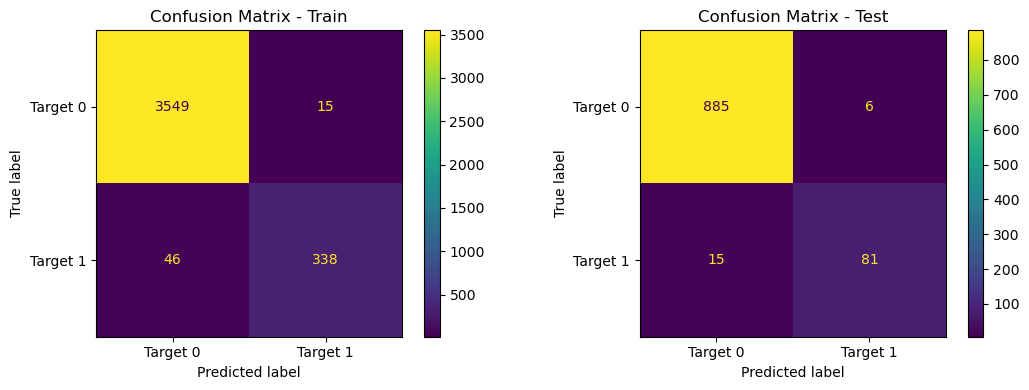

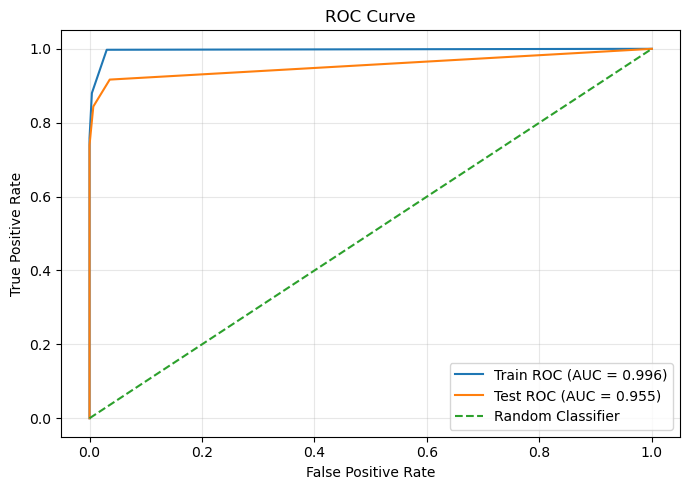

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.984549,0.957507,0.880208,0.917232,0.996362
1,Test,891,96,0.978723,0.931034,0.843750,0.885246,0.954931


In [48]:
results = model_evaluation(
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test,
    KNN_Model_drop
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [49]:
# KNN Model
KNN_Model = KNeighborsClassifier(n_neighbors=5)

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    KNN_Model,
    x_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame for each fold
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Add mean and standard deviation
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].mean(),
    cv_df['Precision'].mean(),
    cv_df['Recall'].mean(),
    cv_df['F1_Score'].mean()
]

cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:-1].std(),
    cv_df['Precision'].iloc[:-1].std(),
    cv_df['Recall'].iloc[:-1].std(),
    cv_df['F1_Score'].iloc[:-1].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.974684,0.913043,0.818182,0.863014
1,2,0.970886,0.921875,0.766234,0.836879
2,3,0.979747,0.969231,0.818182,0.887324
3,4,0.977186,0.983333,0.776316,0.867647
4,5,0.965779,0.867647,0.766234,0.813793
5,Mean,0.973656,0.931026,0.789029,0.853731
6,Std,0.005485,0.046421,0.026929,0.028668


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🌳 Creating Decision Tree Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, a 
<b>Decision Tree Classifier</b> is built to predict whether a customer is likely to accept a 
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

The Decision Tree model learns a set of 
<b>if-then decision rules</b> from the training data by splitting customers based on their 
features. The model is trained using the prepared features and the 
<b>Personal Loan</b> target variable.

</p>

<p style="font-size:16px; line-height:1.8;">

After training, the model is evaluated on unseen test data using appropriate classification 
metrics such as <b>Accuracy, Precision, Recall, and F1-Score</b>. 
These metrics help measure how effectively the model identifies customers who are likely to 
accept a personal loan.

</p>

</div>

In [111]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [112]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [113]:
clf=DecisionTreeClassifier(random_state=0,criterion="entropy",max_depth=6,min_samples_split=2,min_samples_leaf=2)

In [114]:
clf.fit(x_train,y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [115]:
y_pred=clf.predict(x_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [116]:
def model_evaluation(x_train, x_test, y_train, y_test, clf):

    # Predictions
    y_train_pred = clf.predict(x_train)
    y_test_pred = clf.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = clf.predict_proba(x_train)[:, 1]
    y_test_prob = clf.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

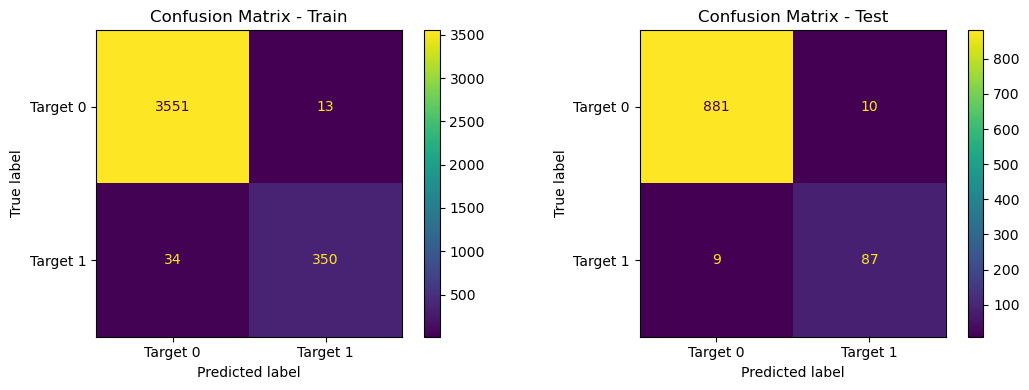

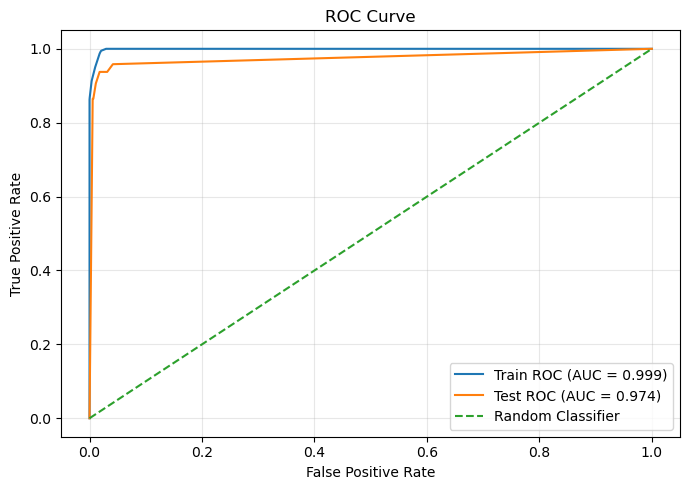

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.988095,0.964187,0.911458,0.937082,0.998854
1,Test,891,96,0.980750,0.896907,0.906250,0.901554,0.974286


In [117]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    clf
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [141]:
# Decision Tree Model
DT_Model = DecisionTreeClassifier(
    max_depth=6,
    random_state=0,
    min_samples_split=2,
    min_samples_leaf=2,
   
)

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    DT_Model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame for each fold
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Add Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].mean(),
    cv_df['Precision'].mean(),
    cv_df['Recall'].mean(),
    cv_df['F1_Score'].mean()
]

# Add Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:-1].std(),
    cv_df['Precision'].iloc[:-1].std(),
    cv_df['Recall'].iloc[:-1].std(),
    cv_df['F1_Score'].iloc[:-1].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.983544,0.921053,0.909091,0.915033
1,2,0.983544,0.944444,0.883117,0.912752
2,3,0.975949,0.914286,0.831169,0.870748
3,4,0.980989,0.929577,0.868421,0.897959
4,5,0.986058,0.934211,0.922078,0.928105
5,Mean,0.982017,0.928714,0.882775,0.904919
6,Std,0.003836,0.011676,0.035730,0.021893


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [122]:
feature_names = [
    'Age',
    'Income',
    'Family',
    'CCAvg',
    'Education',
    'Mortgage',
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

In [123]:
def drop_column_plot(clf, x_train, y_train, x_test, y_test, feature_names):

    results = []

    # Base F1 Score
    base_f1 = f1_score(
        y_test,
        clf.predict(x_test)
    )

    x_train_df = pd.DataFrame(
        x_train,
        columns=feature_names
    )

    x_test_df = pd.DataFrame(
        x_test,
        columns=feature_names
    )

    for column in feature_names:

        x_train_drop = x_train_df.drop(
            columns=[column]
        ).values

        x_test_drop = x_test_df.drop(
            columns=[column]
        ).values

        model_drop = DecisionTreeClassifier(
            random_state=clf.random_state,
            max_depth=clf.max_depth
        )

        model_drop.fit(
            x_train_drop,
            y_train
        )

        y_pred_drop = model_drop.predict(
            x_test_drop
        )

        f1_drop = f1_score(
            y_test,
            y_pred_drop
        )

        importance = base_f1 - f1_drop

        results.append({
            'Feature': column,
            'Importance': importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)

    # Plot
    plt.figure(figsize=(10, 7))

    plt.barh(
        importance_df['Feature'],
        importance_df['Importance']
    )

    plt.axvline(
        x=0,
        linestyle='--'
    )

    plt.xlabel('F1 Score Importance')
    plt.ylabel('Feature')
    plt.title('Drop Column Feature Importance - Decision Tree')

    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

    # DataFrame
    display(
        importance_df.style.format({
            'Importance': '{:.4f}'
        })
    )

    return importance_df

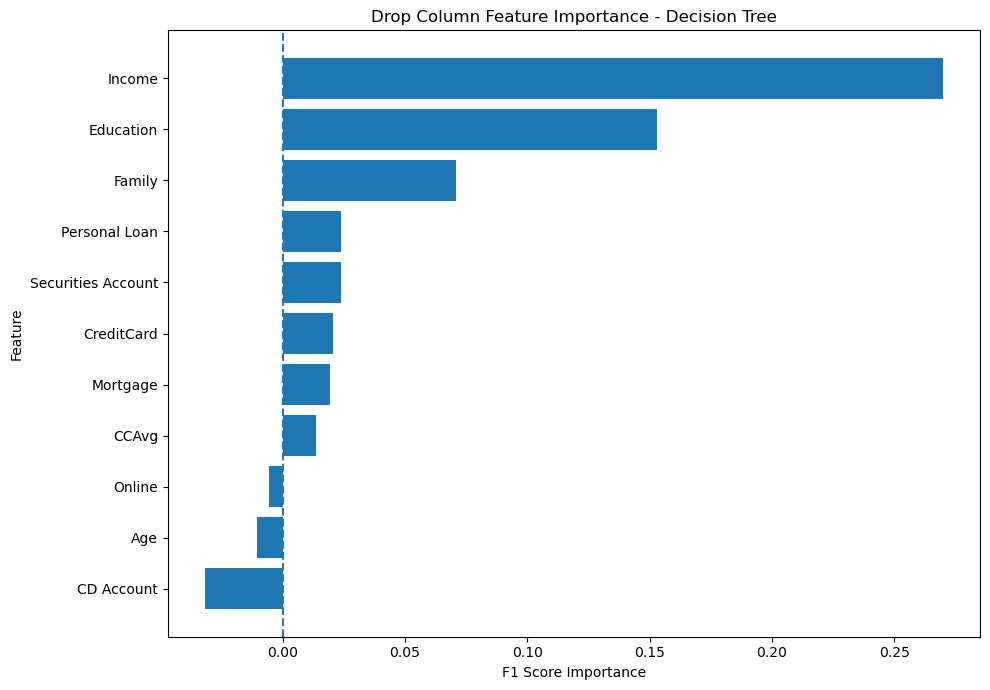

,Feature,Importance
0,Income,0.2700
1,Education,0.1531
2,Family,0.0710
3,Personal Loan,0.0240
4,Securities Account,0.0240
5,CreditCard,0.0207
6,Mortgage,0.0195
7,CCAvg,0.0139
8,Online,-0.0057
9,Age,-0.0104


In [124]:
importance_df = drop_column_plot(
    clf,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
)

In [125]:
data6 = data4.drop(columns=['Online', 'Age', 'CD Account'])
data6

,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CreditCard
0,49,4,1.6,1,0,0,1,0
1,34,3,1.5,1,0,0,1,0
2,11,1,1.0,1,0,0,0,0
3,100,1,2.7,2,0,0,0,0
4,45,4,1.0,2,0,0,0,1
...,...,...,...,...,...,...,...,...
4995,40,1,1.9,3,0,0,0,0
4996,15,4,0.4,1,85,0,0,0
4997,24,2,0.3,3,0,0,0,0
4998,49,3,0.5,2,0,0,0,0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating Model After Drop Column Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">
After evaluating the features using <b>Drop Column Feature Importance</b>,
the importance of each feature was determined based on its effect on the
<b>F1 Score</b>. Features with a higher importance had a greater contribution
to the model's predictive performance.
</p>

<p style="font-size:16px; line-height:1.8;">
Based on the results, the less important features can be removed from the
dataset, and the KNN model can then be trained again using the remaining
features. This helps create a simpler model while maintaining the most
important information for predicting <b>Personal Loan</b>.
</p>

<p style="font-size:16px; line-height:1.8;">
After dropping the selected features, the model was recreated and evaluated
again using the <b>F1 Score</b> to determine whether the reduced feature set
improved or maintained the model's performance.
</p>

</div>

In [126]:
x=data6.drop("Personal Loan",axis=1)
y=data6["Personal Loan"]

In [112]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [134]:
clf_drop=DecisionTreeClassifier(random_state=0,criterion="entropy",max_depth=6,min_samples_split=2,min_samples_leaf=2)

In [135]:
clf_drop.fit(x_train,y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [136]:
y_pred=clf_drop.predict(x_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [137]:
def model_evaluation(x_train, x_test, y_train, y_test, clf_drop):

    # Predictions
    y_train_pred = clf.predict(x_train)
    y_test_pred = clf.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = clf.predict_proba(x_train)[:, 1]
    y_test_prob = clf.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

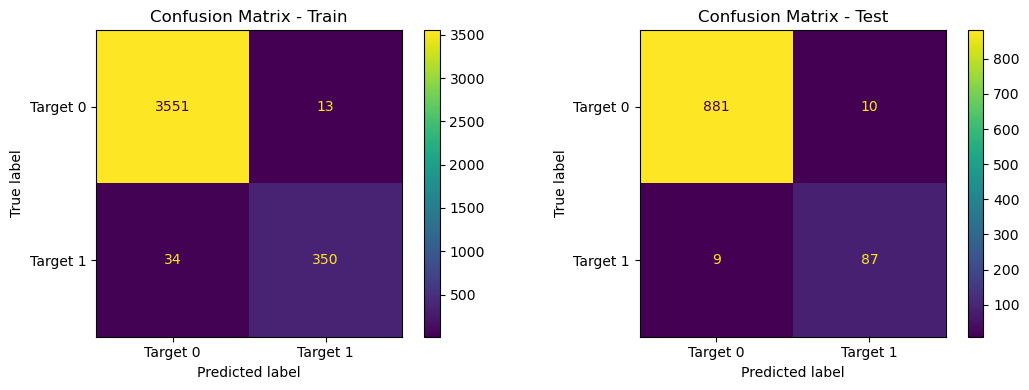

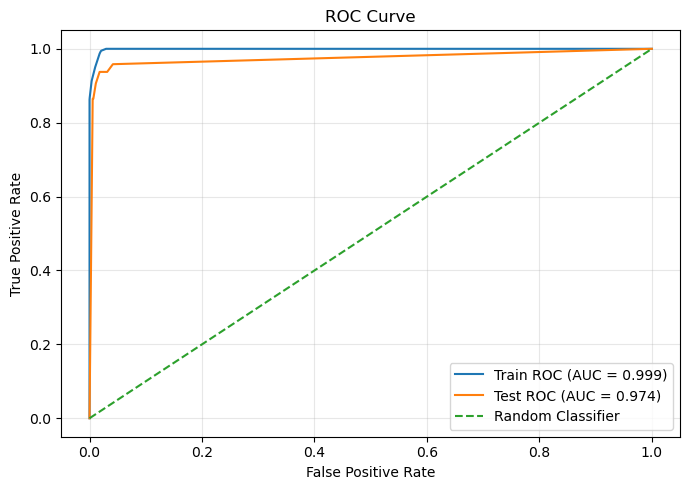

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.988095,0.964187,0.911458,0.937082,0.998854
1,Test,891,96,0.980750,0.896907,0.906250,0.901554,0.974286


In [138]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    clf_drop
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [143]:
# Decision Tree Model
DT_Model = DecisionTreeClassifier(
    max_depth=6,
    random_state=0,
    min_samples_split=2,
    min_samples_leaf=2,
   
)

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    DT_Model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame for each fold
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Add Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].mean(),
    cv_df['Precision'].mean(),
    cv_df['Recall'].mean(),
    cv_df['F1_Score'].mean()
]

# Add Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:-1].std(),
    cv_df['Precision'].iloc[:-1].std(),
    cv_df['Recall'].iloc[:-1].std(),
    cv_df['F1_Score'].iloc[:-1].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.983544,0.921053,0.909091,0.915033
1,2,0.983544,0.944444,0.883117,0.912752
2,3,0.975949,0.914286,0.831169,0.870748
3,4,0.980989,0.929577,0.868421,0.897959
4,5,0.986058,0.934211,0.922078,0.928105
5,Mean,0.982017,0.928714,0.882775,0.904919
6,Std,0.003836,0.011676,0.035730,0.021893


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🌲 Creating Random Forest Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, a 
<b>Random Forest Classifier</b> is built to predict whether a customer is likely to accept a 
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

The Random Forest model combines multiple 
<b>Decision Trees</b> and combines their predictions to make a more reliable classification.
Each tree is trained using different samples and feature combinations from the training data.

</p>

<p style="font-size:16px; line-height:1.8;">

After training, the model is evaluated on unseen test data using appropriate classification 
metrics such as <b>Accuracy, Precision, Recall, and F1-Score</b>.
These metrics help measure how effectively the model identifies customers who are likely to 
accept a personal loan.

</p>

</div>

In [144]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [145]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y)

In [146]:
rf=RandomForestClassifier(n_estimators=50,criterion="entropy",max_depth=8,random_state=0,min_samples_leaf=2,min_samples_split=2)

In [147]:
rf.fit(x_train,y_train)

,n_estimators,50
,criterion,'entropy'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [148]:
y_pred=rf.predict(x_test)
y_pred

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [149]:
def model_evaluation(x_train, x_test, y_train, y_test, rf):

    # Predictions
    y_train_pred = rf.predict(x_train)
    y_test_pred = rf.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = rf.predict_proba(x_train)[:, 1]
    y_test_prob = rf.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

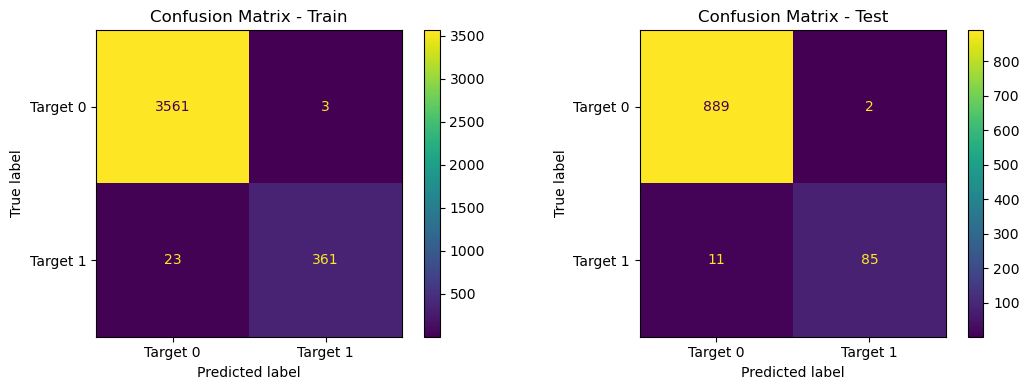

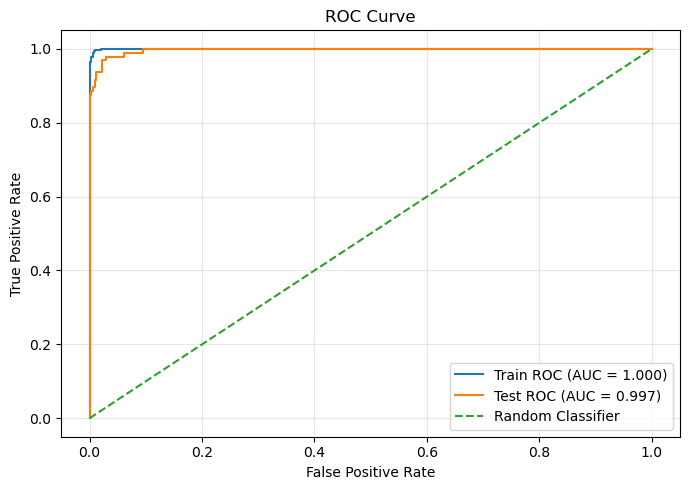

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.993414,0.991758,0.940104,0.965241,0.999722
1,Test,891,96,0.986829,0.977011,0.885417,0.928962,0.996738


In [150]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    rf
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [159]:
feature_names = [
    'Age',
    'Income',
    'Family',
    'CCAvg',
    'Education',
    'Mortgage',
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

In [218]:

def drop_column_plot(
    rf,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
):

    results = []

    # Base F1 Score
    base_f1 = f1_score(
        y_test,
        rf.predict(x_test)
    )

    x_train_df = pd.DataFrame(
        x_train,
        columns=feature_names
    )

    x_test_df = pd.DataFrame(
        x_test,
        columns=feature_names
    )

    for column in feature_names:

        x_train_drop = x_train_df.drop(
            columns=[column]
        ).values

        x_test_drop = x_test_df.drop(
            columns=[column]
        ).values

        model_drop = RandomForestClassifier(
            n_estimators=rf.n_estimators,
            criterion=rf.criterion,
            max_depth=rf.max_depth,
            random_state=rf.random_state,
            min_samples_leaf=rf.min_samples_leaf,
            min_samples_split=rf.min_samples_split
        )

        model_drop.fit(
            x_train_drop,
            y_train
        )

        y_pred_drop = model_drop.predict(
            x_test_drop
        )

        f1_drop = f1_score(
            y_test,
            y_pred_drop
        )

        importance = base_f1 - f1_drop

        results.append({
            'Feature': column,
            'Importance': importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)

    # Plot
    plt.figure(figsize=(10, 7))

    plt.barh(
        importance_df['Feature'],
        importance_df['Importance']
    )

    plt.axvline(
        x=0,
        linestyle='--'
    )

    plt.xlabel('F1 Score Importance')
    plt.ylabel('Feature')
    plt.title('Drop Column Feature Importance - Random Forest')

    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

    # Display DataFrame
    display(
        importance_df.style.format({
            'Importance': '{:.4f}'
        })
    )

    return importance_df

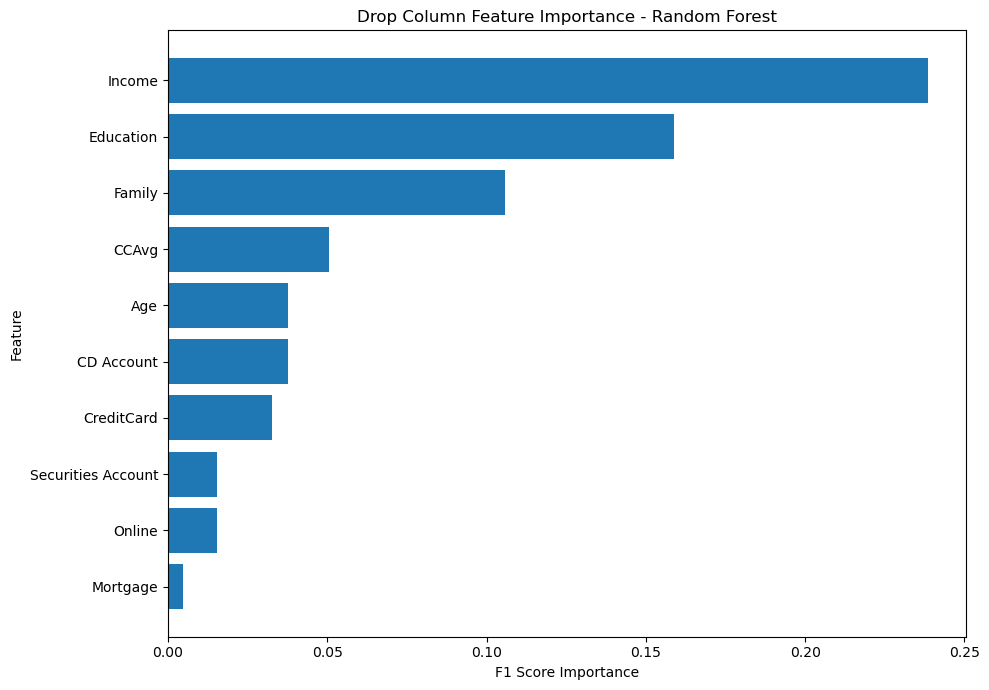

,Feature,Importance
0,Income,0.2386
1,Education,0.1590
2,Family,0.1059
3,CCAvg,0.0504
4,Age,0.0376
5,CD Account,0.0376
6,CreditCard,0.0326
7,Securities Account,0.0153
8,Online,0.0153
9,Mortgage,0.0047


In [219]:
rf_importance = drop_column_plot(
    rf,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
)


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Drop-Column Feature Importance Analysis
</h2>

<p style="font-size:16px; line-height:1.8;">

Based on the <b>Drop-Column Feature Importance</b> results, 
no features were identified as having a negative impact on the model's 
<b>F1-Score</b>.

</p>

<p style="font-size:16px; line-height:1.8;">

This indicates that removing any feature did not improve the model's 
F1-Score compared to the baseline model. Therefore, all evaluated features 
were retained based on this analysis.

</p>

</div>



<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [162]:
# Random Forest Model
rf_drop = RandomForestClassifier(
    n_estimators=50,
    criterion="entropy",
    max_depth=8,
    random_state=0,
    min_samples_leaf=2,
    min_samples_split=2
)

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    rf_drop,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame for each fold
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Add Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].mean(),
    cv_df['Precision'].mean(),
    cv_df['Recall'].mean(),
    cv_df['F1_Score'].mean()
]

# Add Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:-1].std(),
    cv_df['Precision'].iloc[:-1].std(),
    cv_df['Recall'].iloc[:-1].std(),
    cv_df['F1_Score'].iloc[:-1].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.982278,1.000000,0.818182,0.900000
1,2,0.994937,0.986667,0.961039,0.973684
2,3,0.989873,0.960000,0.935065,0.947368
3,4,0.979721,0.928571,0.855263,0.890411
4,5,0.982256,0.984615,0.831169,0.901408
5,Mean,0.985813,0.971971,0.880144,0.922574
6,Std,0.006364,0.028232,0.064065,0.036121


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🚀 Creating AdaBoost Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, an 
<b>AdaBoost Classifier</b> is built to predict whether a customer is likely to accept a 
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

The AdaBoost model combines multiple 
<b>weak learners</b> sequentially to improve classification performance.
Each new learner focuses more on the customers that were incorrectly classified 
by previous learners, allowing the model to gradually improve its predictions.

</p>

<p style="font-size:16px; line-height:1.8;">

After training, the model is evaluated on unseen test data using appropriate classification 
metrics such as <b>Accuracy, Precision, Recall, and F1-Score</b>.
These metrics help measure how effectively the model identifies customers who are likely to 
accept a personal loan.

</p>

</div>

In [163]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [177]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [178]:
DT=DecisionTreeClassifier(criterion="entropy",random_state=0,max_depth=4)

In [179]:
ada_model=AdaBoostClassifier(estimator=DT,random_state=0,n_estimators=10,learning_rate=0.5)

In [180]:
ada_model.fit(x_train,y_train)

,estimator,DecisionTreeC...andom_state=0)
,n_estimators,10
,learning_rate,0.5
,algorithm,'deprecated'
,random_state,0
,criterion,'entropy'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [181]:
y_pred=ada_model.predict(x_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [188]:
def model_evaluation(x_train, x_test, y_train, y_test, ada_model):

    # Predictions
    y_train_pred = ada_model.predict(x_train)
    y_test_pred = ada_model.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = ada_model.predict_proba(x_train)[:, 1]
    y_test_prob = ada_model.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

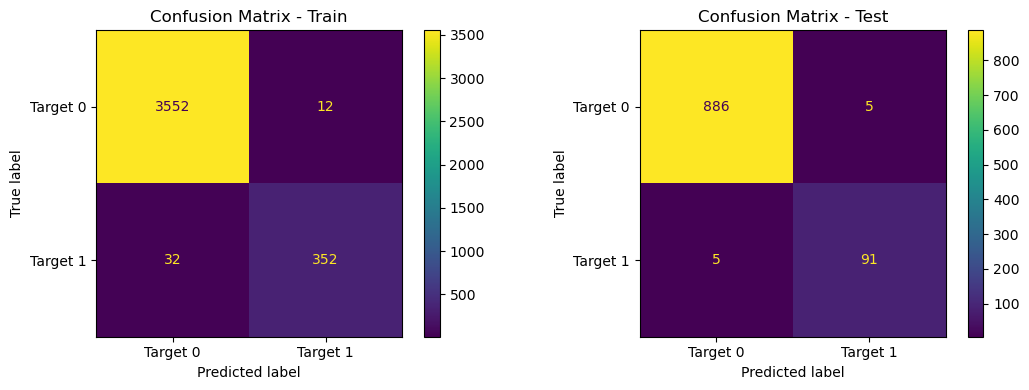

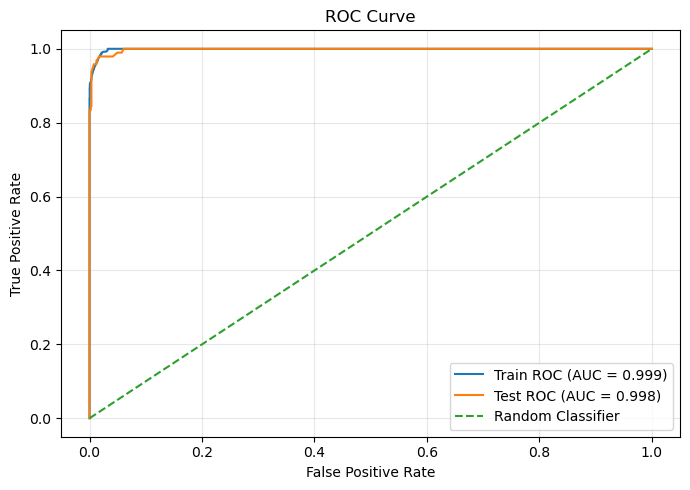

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.988855,0.967033,0.916667,0.941176,0.99888
1,Test,891,96,0.989868,0.947917,0.947917,0.947917,0.99817


In [189]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    ada_model
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [190]:
feature_names = [
    'Age',
    'Income',
    'Family',
    'CCAvg',
    'Education',
    'Mortgage',
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

In [191]:

def drop_column_plot(
    ada_model,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
):
    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn.ensemble import AdaBoostClassifier
    from sklearn.metrics import f1_score

    # Convert data to DataFrames
    x_train_df = pd.DataFrame(x_train, columns=feature_names)
    x_test_df = pd.DataFrame(x_test, columns=feature_names)

    # Base F1 Score
    base_f1 = f1_score(
        y_test,
        ada_model.predict(x_test_df)
    )

    results = []

    for column in feature_names:

        # Drop one feature
        x_train_drop = x_train_df.drop(columns=[column])
        x_test_drop = x_test_df.drop(columns=[column])

        # Create a new AdaBoost model
        model_drop = AdaBoostClassifier(
            n_estimators=ada_model.n_estimators,
            learning_rate=ada_model.learning_rate,
            random_state=ada_model.random_state
        )

        # Train and predict
        model_drop.fit(x_train_drop, y_train)
        y_pred_drop = model_drop.predict(x_test_drop)

        # Calculate feature importance
        f1_drop = f1_score(y_test, y_pred_drop)
        importance = base_f1 - f1_drop

        results.append({
            "Feature": column,
            "Importance": importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    # Plot
    plt.figure(figsize=(10, 7))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )
    plt.axvline(x=0, linestyle="--")
    plt.xlabel("F1 Score Importance")
    plt.ylabel("Feature")
    plt.title("Drop Column Feature Importance - AdaBoost")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    display(importance_df.style.format({
        "Importance": "{:.4f}"
    }))

    return importance_df

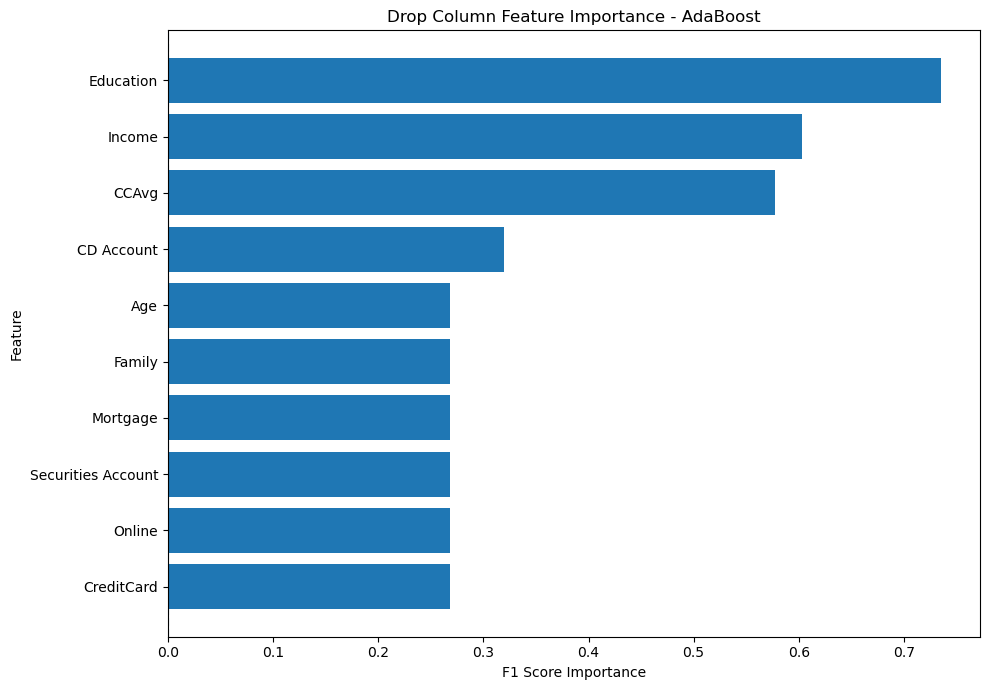

,Feature,Importance
0,Education,0.7355
1,Income,0.6031
2,CCAvg,0.5769
3,CD Account,0.3193
4,Age,0.2682
5,Family,0.2682
6,Mortgage,0.2682
7,Securities Account,0.2682
8,Online,0.2682
9,CreditCard,0.2682


In [194]:
ada_importance = drop_column_plot(
    ada_model,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
)

In [193]:
feature_names = ada_model.feature_names_in_.tolist()

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Drop Column Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

The Drop Column Feature Importance analysis was performed to evaluate the contribution of 
each feature to the <b>Decision Tree</b> model based on the F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

The results show that <b>none of the features had a negative importance value</b>. 
This means that removing any feature did not improve the model's F1-Score compared with 
the baseline model.

</p>

<p style="font-size:16px; line-height:1.8;">

Therefore, all features provided a non-negative contribution to the model's predictive 
performance, and no feature was identified as having a negative impact based on the 
Drop Column Feature Importance analysis.

</p>

</div>

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [195]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    ada_model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].mean(),
    cv_df['Precision'].mean(),
    cv_df['Recall'].mean(),
    cv_df['F1_Score'].mean()
]

# Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:-1].std(),
    cv_df['Precision'].iloc[:-1].std(),
    cv_df['Recall'].iloc[:-1].std(),
    cv_df['F1_Score'].iloc[:-1].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.979747,0.896104,0.896104,0.896104
1,2,0.987342,0.946667,0.922078,0.934211
2,3,0.981013,0.942857,0.857143,0.897959
3,4,0.982256,0.907895,0.907895,0.907895
4,5,0.986058,0.971429,0.883117,0.925170
5,Mean,0.983283,0.932990,0.893267,0.912268
6,Std,0.003275,0.030628,0.024800,0.016831



<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🚀 Creating SVM Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, a
<b>Support Vector Machine (SVM) Classifier</b> is built to predict whether a customer is likely to accept a
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

The SVM model identifies an optimal 
<b>decision boundary (hyperplane)</b> that separates customers into different classes.
It aims to maximize the margin between the classes, using the closest data points,
known as <b>support vectors</b>, to determine the decision boundary.

</p>

<p style="font-size:16px; line-height:1.8;">

After training, the model is evaluated on unseen test data using appropriate classification
metrics such as <b>Accuracy, Precision, Recall, and F1-Score</b>.
These metrics help measure how effectively the model identifies customers who are likely to
accept a personal loan.

</p>

</div>



In [196]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [197]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [198]:
scaler=StandardScaler()

In [199]:
scaler.fit(x_train)

,copy,True
,with_mean,True
,with_std,True


In [200]:
x_train_scaled=scaler.transform(x_train)

In [201]:
x_test_scaled=scaler.transform(x_test)

In [220]:
classifierr=SVC(kernel="rbf",random_state=0)

In [221]:
classifierr.fit(x_train_scaled,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [222]:
y_pred=classifierr.predict(x_test_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [223]:
def model_evaluation(x_train_scaled, x_test_scaled, y_train, y_test, classifierr):

    # Predictions
    y_train_pred = ada_model.predict(x_train)
    y_test_pred = ada_model.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = ada_model.predict_proba(x_train)[:, 1]
    y_test_prob = ada_model.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],

        'Target_0_Count': [
            train_target_0,
            test_target_0
        ],

        'Target_1_Count': [
            train_target_1,
            test_target_1
        ],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [
            train_auc,
            test_auc
        ]
    })

    # =========================
    # Confusion Matrices
    # =========================

    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[0],
        values_format='d'
    )

    axes[0].set_title('Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(
        ax=axes[1],
        values_format='d'
    )

    axes[1].set_title('Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # =========================
    # ROC Curve
    # =========================

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train,
        tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test,
        tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    # Random classifier line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

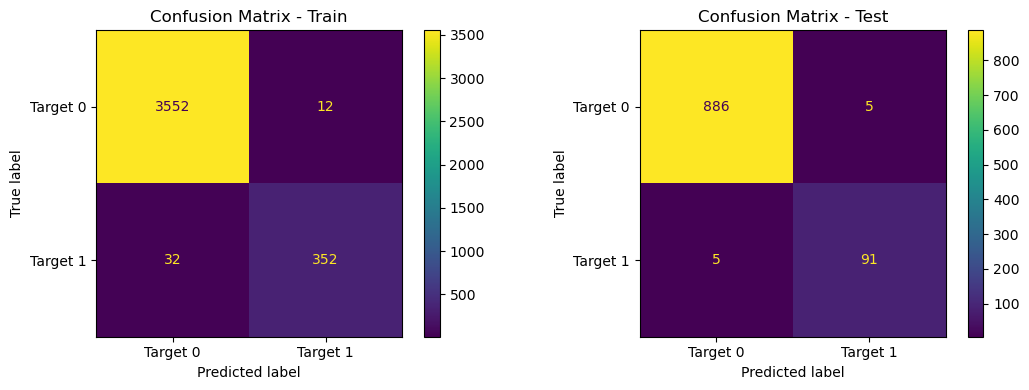

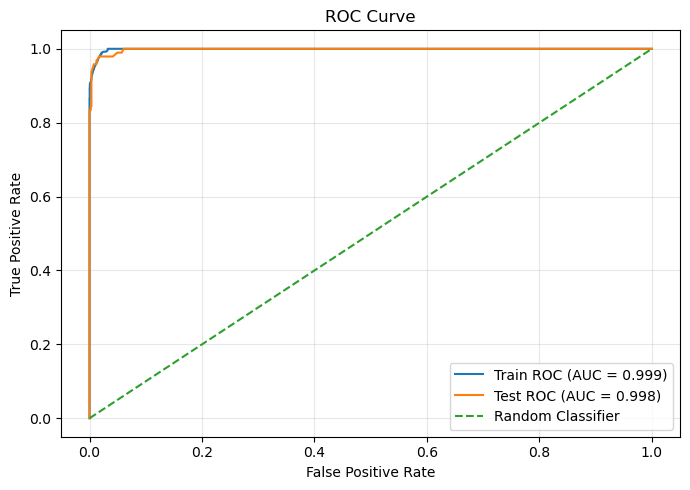

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.988855,0.967033,0.916667,0.941176,0.99888
1,Test,891,96,0.989868,0.947917,0.947917,0.947917,0.99817


In [224]:
results = model_evaluation(
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test,
    classifierr
)

results

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [232]:
# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    classifierr,
    x_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].iloc[:5].mean(),
    cv_df['Precision'].iloc[:5].mean(),
    cv_df['Recall'].iloc[:5].mean(),
    cv_df['F1_Score'].iloc[:5].mean()
]

# Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:5].std(),
    cv_df['Precision'].iloc[:5].std(),
    cv_df['Recall'].iloc[:5].std(),
    cv_df['F1_Score'].iloc[:5].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.967089,0.918033,0.727273,0.811594
1,2,0.969620,0.895522,0.779221,0.833333
2,3,0.969620,0.981818,0.701299,0.818182
3,4,0.977186,0.983333,0.776316,0.867647
4,5,0.975919,0.983333,0.766234,0.861314
5,Mean,0.971887,0.952408,0.750068,0.838414
6,Std,0.004406,0.042413,0.034272,0.025167


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [207]:
feature_names = [
    'Age',
    'Income',
    'Family',
    'CCAvg',
    'Education',
    'Mortgage',
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

In [228]:
def drop_column_plot(
    classifierr,
    x_train_scaled,
    y_train,
    x_test_scaled,
    y_test,
    feature_names
):
    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn.base import clone
    from sklearn.metrics import f1_score

    x_train_df = pd.DataFrame(
        x_train_scaled,
        columns=feature_names
    )
    x_test_df = pd.DataFrame(
        x_test_scaled,
        columns=feature_names
    )

    # Base F1 Score
    base_f1 = f1_score(
        y_test,
        classifierr.predict(x_test_scaled)
    )

    results = []

    for column in feature_names:

        # Drop one feature
        x_train_drop = x_train_df.drop(columns=[column])
        x_test_drop = x_test_df.drop(columns=[column])

        # Create a new SVM model
        model_drop = clone(classifierr)

        # Train and predict
        model_drop.fit(x_train_drop, y_train)
        y_pred_drop = model_drop.predict(x_test_drop)

        # Calculate feature importance
        f1_drop = f1_score(y_test, y_pred_drop)
        importance = base_f1 - f1_drop

        results.append({
            "Feature": column,
            "Importance": importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    # Plot
    plt.figure(figsize=(10, 7))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )
    plt.axvline(x=0, linestyle="--")
    plt.xlabel("F1 Score Importance")
    plt.ylabel("Feature")
    plt.title("Drop Column Feature Importance - SVM")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    display(importance_df.style.format({
        "Importance": "{:.4f}"
    }))

    return importance_df

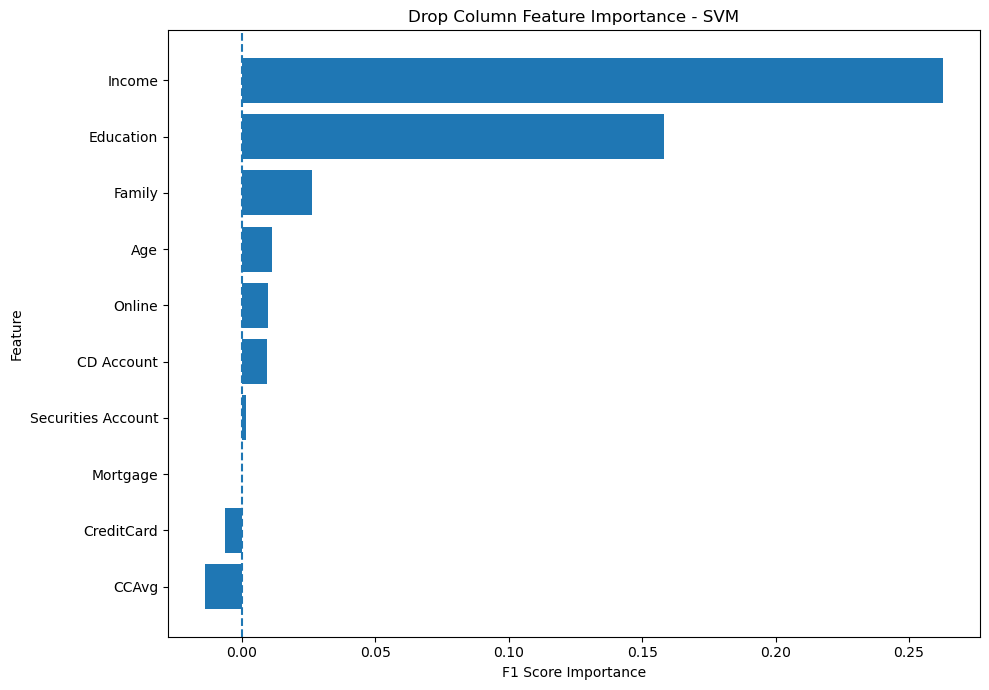

,Feature,Importance
0,Income,0.2628
1,Education,0.1580
2,Family,0.0262
3,Age,0.0114
4,Online,0.0098
5,CD Account,0.0095
6,Securities Account,0.0014
7,Mortgage,0.0000
8,CreditCard,-0.0064
9,CCAvg,-0.0139


In [229]:
ada_importance = drop_column_plot(
    classifierr,
    x_train_scaled,
    y_train,
    x_test_scaled,
    y_test,
    feature_names
)

In [230]:
feature_names = data4.drop(columns=['Personal Loan']).columns.tolist()

In [233]:
data7 = data4.drop(columns=["CreditCard", "CCAvg"])
data7

,Age,Income,Family,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online
0,25,49,4,1,0,0,1,0,0
1,45,34,3,1,0,0,1,0,0
2,39,11,1,1,0,0,0,0,0
3,35,100,1,2,0,0,0,0,0
4,35,45,4,2,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...
4995,29,40,1,3,0,0,0,0,1
4996,30,15,4,1,85,0,0,0,1
4997,63,24,2,3,0,0,0,0,0
4998,65,49,3,2,0,0,0,0,1


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating Model After Drop Column Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">
After evaluating the features using <b>Drop Column Feature Importance</b>,
the importance of each feature was determined based on its effect on the
<b>F1 Score</b>. Features with a higher importance had a greater contribution
to the model's predictive performance.
</p>

<p style="font-size:16px; line-height:1.8;">
Based on the results, the less important features can be removed from the
dataset, and the KNN model can then be trained again using the remaining
features. This helps create a simpler model while maintaining the most
important information for predicting <b>Personal Loan</b>.
</p>

<p style="font-size:16px; line-height:1.8;">
After dropping the selected features, the model was recreated and evaluated
again using the <b>F1 Score</b> to determine whether the reduced feature set
improved or maintained the model's performance.
</p>

</div>

In [235]:
x=data7.drop("Personal Loan",axis=1)
y=data7["Personal Loan"]

In [236]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [237]:
scaler=StandardScaler()

In [238]:
scaler.fit(x_train)

,copy,True
,with_mean,True
,with_std,True


In [239]:
x_train_scaled=scaler.transform(x_train)

In [240]:
x_test_scaled=scaler.transform(x_test)

In [254]:
classifier_drop=SVC(kernel="rbf",random_state=0,probability=True)

In [255]:
classifier_drop.fit(x_train_scaled,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [256]:
y_pred=classifier_drop.predict(x_test_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [263]:

def model_evaluation(
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test,
    classifier_drop
):

    # Predictions
    y_train_pred = classifier_drop.predict(x_train_scaled)
    y_test_pred = classifier_drop.predict(x_test_scaled)

    # Probability predictions for ROC Curve
    y_train_prob = classifier_drop.predict_proba(x_train_scaled)[:, 1]
    y_test_prob = classifier_drop.predict_proba(x_test_scaled)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],
        'Target_0_Count': [train_target_0, test_target_0],
        'Target_1_Count': [train_target_1, test_target_1],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [train_auc, test_auc]
    })

    # Confusion Matrices
    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[0], values_format='d')

    axes[0].set_title('SVM Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[1], values_format='d')

    axes[1].set_title('SVM Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # ROC Curve
    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train, tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test, tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('SVM ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    

    return results



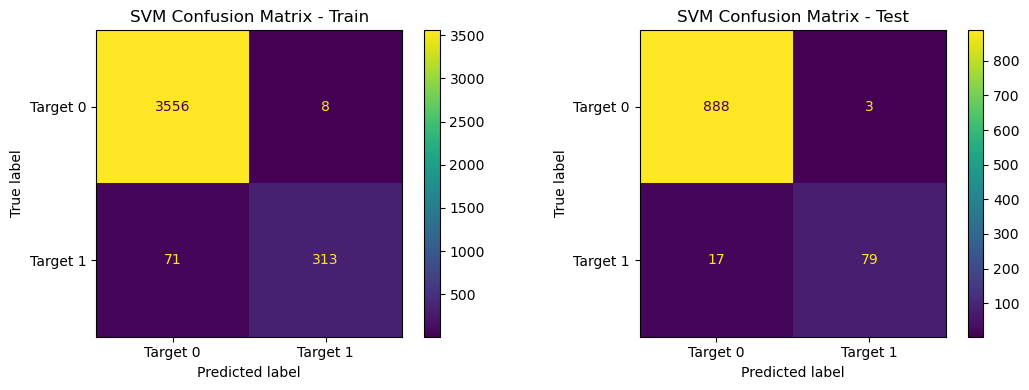

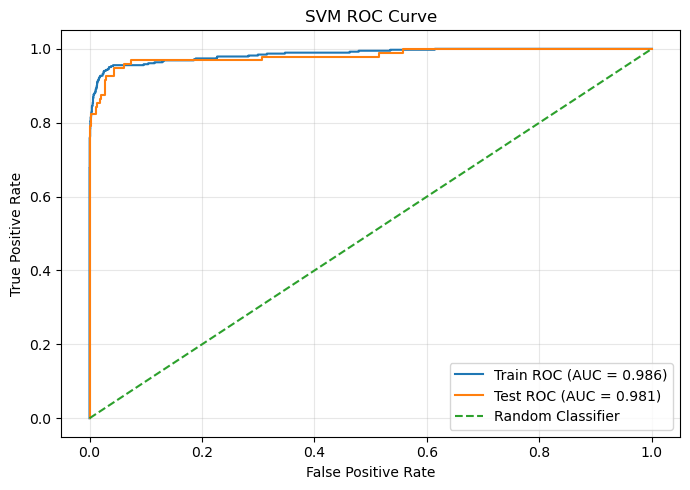

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.979990,0.975078,0.815104,0.887943,0.985704
1,Test,891,96,0.979737,0.963415,0.822917,0.887640,0.980979


In [264]:
results = model_evaluation(
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test,
    classifier_drop
)


display(results)

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [265]:

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    classifier_drop,
    x_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].iloc[:5].mean(),
    cv_df['Precision'].iloc[:5].mean(),
    cv_df['Recall'].iloc[:5].mean(),
    cv_df['F1_Score'].iloc[:5].mean()
]

# Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:5].std(),
    cv_df['Precision'].iloc[:5].std(),
    cv_df['Recall'].iloc[:5].std(),
    cv_df['F1_Score'].iloc[:5].std()
]

cv_df



,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.969620,0.895522,0.779221,0.833333
1,2,0.970886,0.897059,0.792208,0.841379
2,3,0.968354,0.948276,0.714286,0.814815
3,4,0.977186,0.983333,0.776316,0.867647
4,5,0.977186,0.983607,0.779221,0.869565
5,Mean,0.972647,0.941559,0.768250,0.845348
6,Std,0.004240,0.043755,0.030789,0.023324



<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🚀 Creating Naive Bayes Model
</h2>

<p style="font-size:16px; line-height:1.8;">

After completing the data analysis and preprocessing steps, a
<b>Naive Bayes Classifier</b> is built to predict whether a customer is likely to accept a
<b>Personal Loan</b> offer.

</p>

<p style="font-size:16px; line-height:1.8;">

Naive Bayes is a probabilistic classification algorithm based on
<b>Bayes' theorem</b>. It calculates the probability of a customer belonging to each class
based on the available features, assuming that the features are conditionally independent
given the target class.

</p>

<p style="font-size:16px; line-height:1.8;">

The model uses the information available in customer features to estimate the probability
of accepting a personal loan and assigns the customer to the most likely class.

</p>

<p style="font-size:16px; line-height:1.8;">

After training, the model is evaluated on unseen test data using classification metrics
such as <b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics help assess how
effectively the model identifies customers who are likely to accept a personal loan.

</p>

</div>

In [268]:
x=data4.drop("Personal Loan",axis=1)
y=data4["Personal Loan"]

In [269]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [272]:
naive_model=GaussianNB()

In [273]:
naive_model.fit(x_train,y_train)

,priors,None
,var_smoothing,1e-09


In [275]:
y_pred=naive_model.predict(x_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [278]:

def model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    naive_model
):

    # Predictions
    y_train_pred = naive_model.predict(x_train)
    y_test_pred = naive_model.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = naive_model.predict_proba(x_train)[:, 1]
    y_test_prob = naive_model.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],
        'Target_0_Count': [train_target_0, test_target_0],
        'Target_1_Count': [train_target_1, test_target_1],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [train_auc, test_auc]
    })

    # Confusion Matrices
    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[0], values_format='d')

    axes[0].set_title('SVM Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[1], values_format='d')

    axes[1].set_title('SVM Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # ROC Curve
    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train, tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test, tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('SVM ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    

    return results



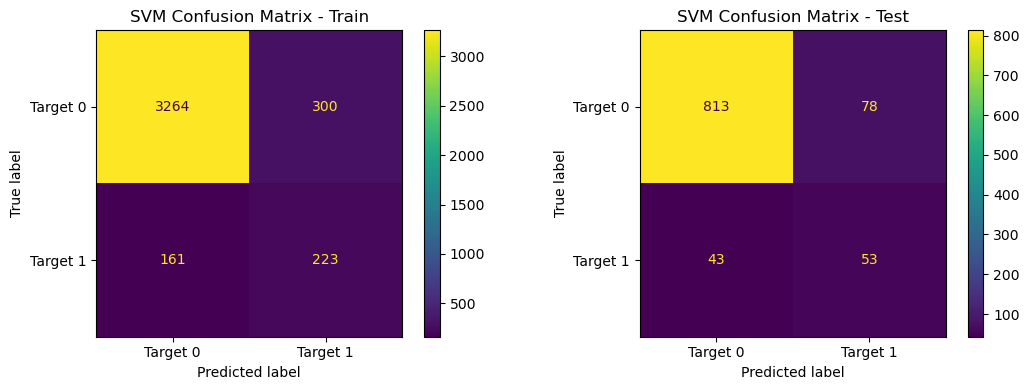

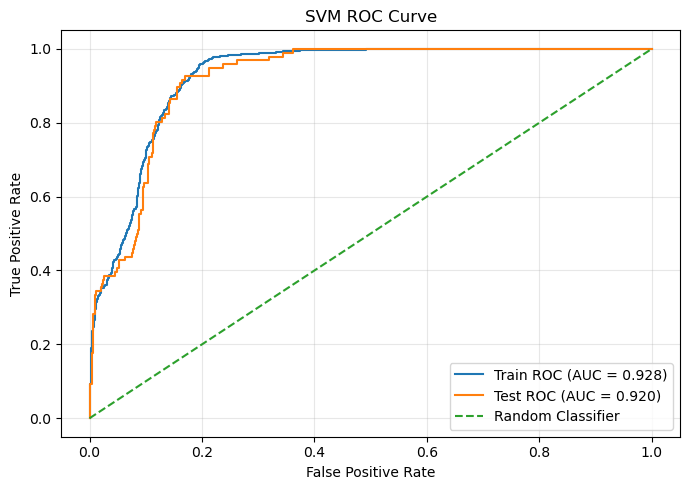

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.883232,0.426386,0.580729,0.491731,0.927665
1,Test,891,96,0.877406,0.404580,0.552083,0.466960,0.919987


In [277]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    naive_model
)


display(results)

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [281]:

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    naive_model,
    x_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].iloc[:5].mean(),
    cv_df['Precision'].iloc[:5].mean(),
    cv_df['Recall'].iloc[:5].mean(),
    cv_df['F1_Score'].iloc[:5].mean()
]

# Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:5].std(),
    cv_df['Precision'].iloc[:5].std(),
    cv_df['Recall'].iloc[:5].std(),
    cv_df['F1_Score'].iloc[:5].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.892405,0.452381,0.493506,0.472050
1,2,0.908861,0.537313,0.467532,0.500000
2,3,0.906329,0.521127,0.480519,0.500000
3,4,0.896071,0.457143,0.421053,0.438356
4,5,0.898606,0.478873,0.441558,0.459459
5,Mean,0.900454,0.489367,0.460834,0.473973
6,Std,0.006939,0.038158,0.029385,0.026635


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📉 Drop Columns & Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">

After evaluating the model, <b>Feature Importance</b> is used to identify which 
features have the greatest impact on the model's predictions.
For the KNN model, <b>Permutation Importance</b> is used to measure the importance 
of each feature based on its effect on the model's F1-Score.

</p>

<p style="font-size:16px; line-height:1.8;">

Features with very low or negative importance can be considered as potential 
candidates for removal. Removing unnecessary features can simplify the dataset 
and may improve the model's performance and generalization.

</p>

<p style="font-size:16px; line-height:1.8;">

After dropping the selected features, the model is trained and evaluated again 
to compare its performance with the original model and determine whether 
removing these features improves the final results.

</p>

</div>

In [207]:
feature_names = [
    'Age',
    'Income',
    'Family',
    'CCAvg',
    'Education',
    'Mortgage',
    'Personal Loan',
    'Securities Account',
    'CD Account',
    'Online',
    'CreditCard'
]

In [282]:
def drop_column_plot(
    naive_model,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
):
    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn.naive_bayes import GaussianNB
    from sklearn.metrics import f1_score

    # Convert data to DataFrames
    x_train_df = pd.DataFrame(x_train, columns=feature_names)
    x_test_df = pd.DataFrame(x_test, columns=feature_names)

    # Base F1 Score
    base_f1 = f1_score(
        y_test,
        naive_model.predict(x_test_df)
    )

    results = []

    for column in feature_names:

        # Drop one feature
        x_train_drop = x_train_df.drop(columns=[column])
        x_test_drop = x_test_df.drop(columns=[column])

        # Create a new Naive Bayes model
        model_drop = GaussianNB()

        # Train and predict
        model_drop.fit(x_train_drop, y_train)
        y_pred_drop = model_drop.predict(x_test_drop)

        # Calculate feature importance
        f1_drop = f1_score(y_test, y_pred_drop)
        importance = base_f1 - f1_drop

        results.append({
            "Feature": column,
            "Importance": importance
        })

    importance_df = pd.DataFrame(results)

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    # Plot
    plt.figure(figsize=(10, 7))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )
    plt.axvline(x=0, linestyle="--")
    plt.xlabel("F1 Score Importance")
    plt.ylabel("Feature")
    plt.title("Drop Column Feature Importance - Naive Bayes")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    display(importance_df.style.format({
        "Importance": "{:.4f}"
    }))

    return importance_df

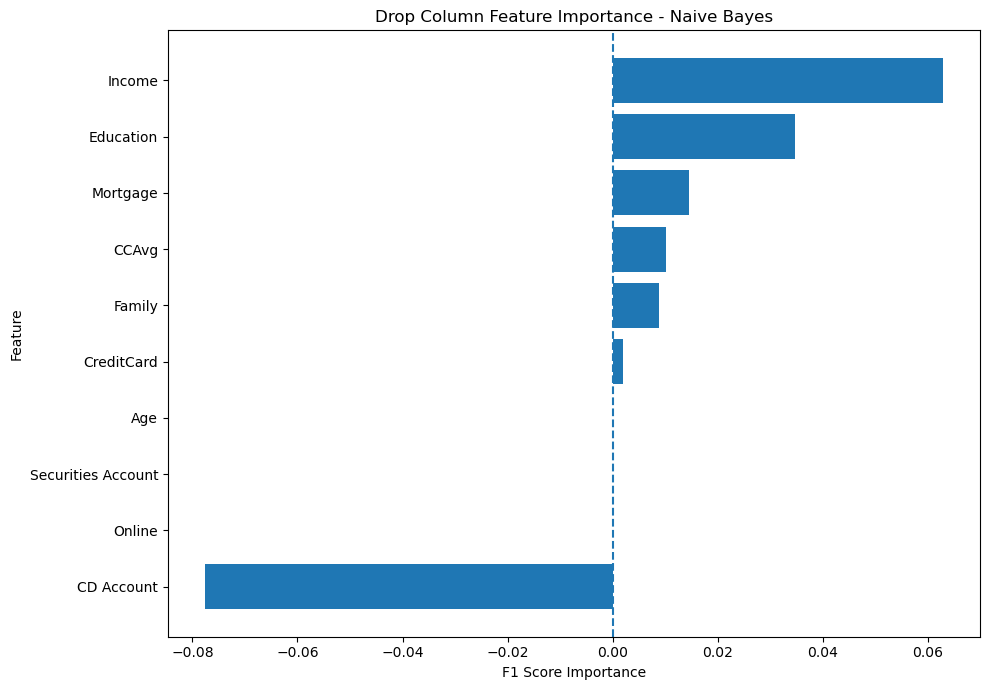

,Feature,Importance
0,Income,0.0629
1,Education,0.0348
2,Mortgage,0.0145
3,CCAvg,0.0101
4,Family,0.0088
5,CreditCard,0.0020
6,Age,0.0000
7,Securities Account,0.0000
8,Online,0.0000
9,CD Account,-0.0776


In [283]:
naive_importance = drop_column_plot(
    naive_model,
    x_train,
    y_train,
    x_test,
    y_test,
    feature_names
)

In [284]:
data7 = data4.drop(columns=["CD Account"])
data7

,Age,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,Online,CreditCard
0,25,49,4,1.6,1,0,0,1,0,0
1,45,34,3,1.5,1,0,0,1,0,0
2,39,11,1,1.0,1,0,0,0,0,0
3,35,100,1,2.7,2,0,0,0,0,0
4,35,45,4,1.0,2,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...
4995,29,40,1,1.9,3,0,0,0,1,0
4996,30,15,4,0.4,1,85,0,0,1,0
4997,63,24,2,0.3,3,0,0,0,0,0
4998,65,49,3,0.5,2,0,0,0,1,0


<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating Model After Drop Column Feature Importance
</h2>

<p style="font-size:16px; line-height:1.8;">
After evaluating the features using <b>Drop Column Feature Importance</b>,
the importance of each feature was determined based on its effect on the
<b>F1 Score</b>. Features with a higher importance had a greater contribution
to the model's predictive performance.
</p>

<p style="font-size:16px; line-height:1.8;">
Based on the results, the less important features can be removed from the
dataset, and the KNN model can then be trained again using the remaining
features. This helps create a simpler model while maintaining the most
important information for predicting <b>Personal Loan</b>.
</p>

<p style="font-size:16px; line-height:1.8;">
After dropping the selected features, the model was recreated and evaluated
again using the <b>F1 Score</b> to determine whether the reduced feature set
improved or maintained the model's performance.
</p>

</div>

In [291]:
x=data7.drop("Personal Loan",axis=1)
y=data7["Personal Loan"]

In [292]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0,stratify=y)

In [293]:
naive_model_drop=GaussianNB()

In [294]:
naive_model_drop.fit(x_train,y_train)

,priors,None
,var_smoothing,1e-09


In [295]:
y_pred=naive_model_drop.predict(x_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Model Evaluation
</h2>

<p style="font-size:16px; line-height:1.8;">

After training the machine learning model, the next step is to evaluate its 
<b>performance and prediction quality</b> on both the training and test datasets.

</p>

<p style="font-size:16px; line-height:1.8;">

The model is evaluated using several performance metrics, including 
<b>Accuracy, Precision, Recall, and F1-Score</b>. These metrics provide a 
more complete understanding of how well the model classifies customers.

</p>

<p style="font-size:16px; line-height:1.8;">

The <b>Confusion Matrix</b> is also used to examine the number of correct and 
incorrect predictions for each target class. Comparing the training and test 
results helps determine whether the model has good generalization and avoids 
<b>overfitting or underfitting</b>.

</p>

</div>

In [296]:

def model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    naive_model_drop
):

    # Predictions
    y_train_pred = naive_model_drop.predict(x_train)
    y_test_pred = naive_model_drop.predict(x_test)

    # Probability predictions for ROC Curve
    y_train_prob = naive_model_drop.predict_proba(x_train)[:, 1]
    y_test_prob = naive_model_drop.predict_proba(x_test)[:, 1]

    # Target counts
    train_target_0 = (y_train == 0).sum()
    train_target_1 = (y_train == 1).sum()

    test_target_0 = (y_test == 0).sum()
    test_target_1 = (y_test == 1).sum()

    # AUC
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)

    # Evaluation DataFrame
    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],
        'Target_0_Count': [train_target_0, test_target_0],
        'Target_1_Count': [train_target_1, test_target_1],

        'Accuracy': [
            accuracy_score(y_train, y_train_pred),
            accuracy_score(y_test, y_test_pred)
        ],

        'Precision': [
            precision_score(y_train, y_train_pred, zero_division=0),
            precision_score(y_test, y_test_pred, zero_division=0)
        ],

        'Recall': [
            recall_score(y_train, y_train_pred, zero_division=0),
            recall_score(y_test, y_test_pred, zero_division=0)
        ],

        'F1_Score': [
            f1_score(y_train, y_train_pred, zero_division=0),
            f1_score(y_test, y_test_pred, zero_division=0)
        ],

        'AUC': [train_auc, test_auc]
    })

    # Confusion Matrices
    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[0], values_format='d')

    axes[0].set_title('SVM Confusion Matrix - Train')

    ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Target 0', 'Target 1']
    ).plot(ax=axes[1], values_format='d')

    axes[1].set_title('SVM Confusion Matrix - Test')

    plt.tight_layout()
    plt.show()

    # ROC Curve
    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr_train, tpr_train,
        label=f'Train ROC (AUC = {train_auc:.3f})'
    )

    plt.plot(
        fpr_test, tpr_test,
        label=f'Test ROC (AUC = {test_auc:.3f})'
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('SVM ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    

    return results



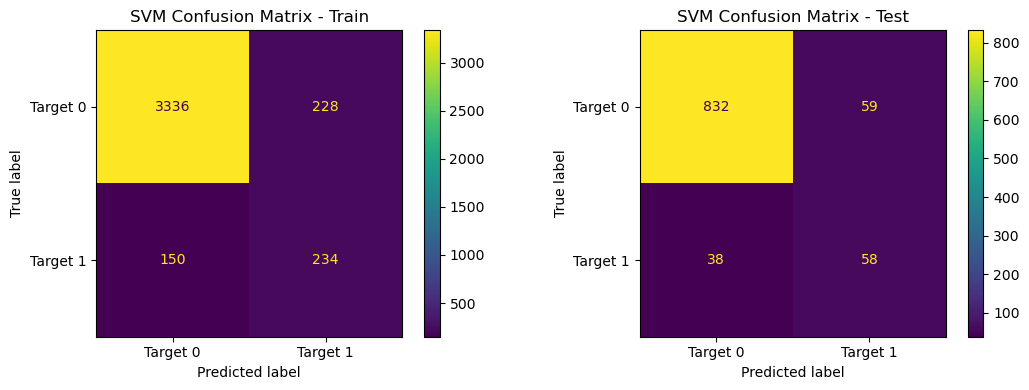

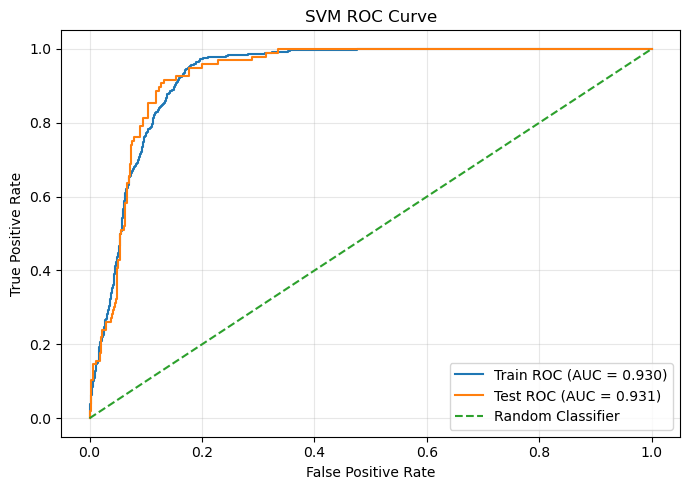

,Dataset,Target_0_Count,Target_1_Count,Accuracy,Precision,Recall,F1_Score,AUC
0,Train,3564,384,0.904255,0.506494,0.609375,0.553191,0.929840
1,Test,891,96,0.901722,0.495726,0.604167,0.544601,0.931327


In [297]:
results = model_evaluation(
    x_train,
    x_test,
    y_train,
    y_test,
    naive_model_drop
)


display(results)

<div style="
background-color:#9fb8d2;
padding:20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🔄 Cross Validation
</h2>

<p style="font-size:16px; line-height:1.8;">
Cross Validation was used to evaluate the stability and reliability of the
KNN model. The training data was divided into multiple folds, allowing the
model to be trained and validated on different subsets of the data.
</p>

<p style="font-size:16px; line-height:1.8;">
In this process, <b>Accuracy, Precision, Recall, and F1 Score</b> were
calculated for each fold. The mean and standard deviation of these metrics
were then used to evaluate the overall performance and consistency of the
model.
</p>

<p style="font-size:16px; line-height:1.8;">
The <b>F1 Score</b> was given particular importance because the
<b>Personal Loan</b> target is imbalanced. Cross Validation helps determine
whether the model performs consistently across different subsets of the
training data.
</p>

</div>

In [298]:
# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Scoring metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1'
}

cv_results = cross_validate(
    naive_model_drop,
    x_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

# Create DataFrame
cv_df = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_results['test_Accuracy'],
    'Precision': cv_results['test_Precision'],
    'Recall': cv_results['test_Recall'],
    'F1_Score': cv_results['test_F1_Score']
})

# Mean
cv_df.loc[len(cv_df)] = [
    'Mean',
    cv_df['Accuracy'].iloc[:5].mean(),
    cv_df['Precision'].iloc[:5].mean(),
    cv_df['Recall'].iloc[:5].mean(),
    cv_df['F1_Score'].iloc[:5].mean()
]

# Standard Deviation
cv_df.loc[len(cv_df)] = [
    'Std',
    cv_df['Accuracy'].iloc[:5].std(),
    cv_df['Precision'].iloc[:5].std(),
    cv_df['Recall'].iloc[:5].std(),
    cv_df['F1_Score'].iloc[:5].std()
]

cv_df

,Fold,Accuracy,Precision,Recall,F1_Score
0,1,0.892405,0.452381,0.493506,0.472050
1,2,0.908861,0.537313,0.467532,0.500000
2,3,0.906329,0.521127,0.480519,0.500000
3,4,0.896071,0.457143,0.421053,0.438356
4,5,0.898606,0.478873,0.441558,0.459459
5,Mean,0.900454,0.489367,0.460834,0.473973
6,Std,0.006939,0.038158,0.029385,0.026635


In [300]:

from IPython.display import display, HTML

html_code = """
<div style="font-family:Segoe UI,Tahoma,sans-serif;
            background:#f7f9fc; border:1px solid #d9e2ef;
            border-radius:16px; padding:25px; color:#263445;
            line-height:1.8;">

    <div style="background:#e3ebf7; border-left:6px solid #5279ad;
                border-radius:10px; padding:18px 22px; margin-bottom:22px;">
        <h2 style="color:#234f85; margin:0 0 8px;">
            Model Evaluation and Comparison
        </h2>
        <p style="margin:0; color:#405570;">
            In this project, 10 classification models were developed and
            evaluated, including the original models and their corresponding
            versions after applying the Drop Column feature selection method.
            The models were compared using F1-score and Accuracy on both
            training and testing datasets.
        </p>
    </div>

    <h3 style="color:#315b8a;">Evaluation Results</h3>

    <div style="overflow-x:auto; border-radius:10px;">
    <table style="width:100%; border-collapse:collapse; background:white;
                  font-size:13px; text-align:center;">
        <thead>
            <tr style="background:#5279ad; color:white;">
                <th style="padding:12px 8px;">Model</th>
                <th style="padding:12px 8px;">F1 Train</th>
                <th style="padding:12px 8px;">F1 Test</th>
                <th style="padding:12px 8px;">Accuracy Train</th>
                <th style="padding:12px 8px;">Accuracy Test</th>
            </tr>
        </thead>
        <tbody>
            <tr style="background:#f2f6fb;">
                <td style="padding:10px;">KNN</td>
                <td>0.87</td><td>0.84</td><td>0.97</td><td>0.97</td>
            </tr>
            <tr>
                <td style="padding:10px;">KNN + Drop Column</td>
                <td>0.97</td><td>0.88</td><td>0.98</td><td>0.97</td>
            </tr>
            <tr style="background:#f2f6fb;">
                <td style="padding:10px;">Decision Tree</td>
                <td>0.93</td><td>0.90</td><td>0.98</td><td>0.98</td>
            </tr>
            <tr>
                <td style="padding:10px;">Decision Tree + Drop Column</td>
                <td>0.93</td><td>0.90</td><td>0.98</td><td>0.98</td>
            </tr>
            <tr style="background:#f2f6fb;">
                <td style="padding:10px;">Random Forest</td>
                <td>0.96</td><td>0.92</td><td>0.99</td><td>0.98</td>
            </tr>
            <tr>
                <td style="padding:10px;">AdaBoost</td>
                <td>0.94</td><td>0.94</td><td>0.98</td><td>0.98</td>
            </tr>
            <tr style="background:#f2f6fb;">
                <td style="padding:10px;">SVM</td>
                <td>0.94</td><td>0.94</td><td>0.98</td><td>0.98</td>
            </tr>
            <tr>
                <td style="padding:10px;">SVM + Drop Column</td>
                <td>0.88</td><td>0.88</td><td>0.97</td><td>0.97</td>
            </tr>
            <tr style="background:#f2f6fb;">
                <td style="padding:10px;">Naive Bayes</td>
                <td>0.49</td><td>0.46</td><td>0.88</td><td>0.87</td>
            </tr>
            <tr>
                <td style="padding:10px;">Naive Bayes + Drop Column</td>
                <td>0.55</td><td>0.54</td><td>0.90</td><td>0.90</td>
            </tr>
        </tbody>
    </table>
    </div>

    <div style="margin-top:24px; background:#e8f3e8;
                border-left:6px solid #6b9b6b; border-radius:10px;
                padding:17px 20px;">
        <h3 style="color:#356b43; margin:0 0 8px;">Key Findings</h3>
        <ul style="margin:0; padding-left:22px;">
            <li><b>AdaBoost and SVM</b> achieved the highest test F1-score (0.94).</li>
            <li><b>Random Forest</b> achieved a test F1-score of 0.92 and test accuracy of 0.98.</li>
            <li><b>KNN + Drop Column</b> improved test F1-score from 0.84 to 0.88.</li>
            <li><b>Decision Tree</b> showed no change in the reported metrics after Drop Column.</li>
            <li><b>SVM + Drop Column</b> had a lower test F1-score than the original SVM.</li>
            <li><b>Naive Bayes</b> improved from 0.46 to 0.54 in test F1-score after Drop Column, but remained weaker than the other models.</li>
        </ul>
    </div>

    <div style="margin-top:20px; background:#fff4df;
                border-left:6px solid #d5a34d; border-radius:10px;
                padding:17px 20px;">
        <h3 style="color:#8a6324; margin:0 0 8px;">Overall Conclusion</h3>
        <p style="margin:0;">
            Based on the reported test results, AdaBoost and SVM provided
            the strongest F1-score, while Random Forest also demonstrated
            strong performance. The effect of Drop Column varied across
            algorithms: it improved KNN and Naive Bayes, had no reported
            effect on Decision Tree, and reduced SVM performance.
            Therefore, feature selection should be evaluated separately
            for each model.
        </p>
    </div>

    <p style="margin:18px 0 0; color:#68788b; font-size:12px;
              text-align:center;">
        Classification Model Comparison | Training and Testing Evaluation
    </p>
</div>
"""

display(HTML(html_code))

Model,F1 Train,F1 Test,Accuracy Train,Accuracy Test
KNN,0.87,0.84,0.97,0.97
KNN + Drop Column,0.97,0.88,0.98,0.97
Decision Tree,0.93,0.90,0.98,0.98
Decision Tree + Drop Column,0.93,0.90,0.98,0.98
Random Forest,0.96,0.92,0.99,0.98
AdaBoost,0.94,0.94,0.98,0.98
SVM,0.94,0.94,0.98,0.98
SVM + Drop Column,0.88,0.88,0.97,0.97
Naive Bayes,0.49,0.46,0.88,0.87
Naive Bayes + Drop Column,0.55,0.54,0.90,0.90
